# WP3 — Modular post-SAMap analysis and species-aware LOF

**ELIXIR BioHackathon Europe 2026 · Project 23 · Work Package 3**  
**Input:** existing mouse–zebrafish `map2` SAMap output. **No SAMap rerun.**

## Run any subsection independently

1. After starting/restarting your Jupyter kernel, run only **Setup 1** (imports), **Setup 2** (configuration), and **Setup 3** (shared reusable functions). These small cells have no expensive computations.
2. Run **any subsequent subsection by itself**, in any order. Each section reads its own inputs, uses a local random generator, closes read-only H5AD handles, and writes its own named CSV/JSON files. You **do not need to rerun B–G to run either LOF method**.
3. Sections that summarize previous results read saved CSVs and clearly report missing outputs; they do not quietly rerun expensive analyses.

### LOF experiments

- **H1 · Directional reference LOF:** Fit `LocalOutlierFactor(novelty=True)` on mouse reference cells; score **unseen zebrafish cells**, and reverse. Compare scores with held-out *reference-species* controls.
- **H2 · Species-aware neighborhood separation:** Compare distances to the kth neighbor of the same species and the other species in the **joint** manifold. This is a **custom cross-species separation statistic, not classical LOF**. Balanced species-specific neighbor banks and self-exclusion are used.
- **H3 · Candidate coherent components:** Build mutual within-species kNN links among high-separation cells; report connected components and annotation composition. This is an exploratory cluster screen, not definitive cell-type discovery.
- **H4 · Compare methods:** Join previously saved outputs to SAMap mapping strengths.

**Joint coordinates for this version:** You confirmed that the mouse and zebrafish cells are already represented together in `adata.obsm["X_umap"]`. **H1, H2, and H3 now use this stored 2D joint UMAP directly by default**; no separate embedding export or SAMap rerun is required. The default is to preserve the existing UMAP axis geometry (no axis-wise scaling). A UMAP is still a nonlinear visualization projection, not the original high-dimensional SAMap latent representation: neighborhood distances, densities, and apparent species separation may be distorted. Interpret these results as **exploratory species separation on the displayed UMAP**, not validated non-homology. Graph-SVD remains disabled.

Low alignment, high LOF, or strong species separation ≠ proof of absent evolutionary homology. Validate against sampling, batch, stage, mapping and gene homology effects.

## Setup 1 — Imports (run once after restarting the kernel)

The three setup cells below are the *only* shared prerequisites. All later analyses can be executed independently of one another.

In [1]:
from pathlib import Path
from contextlib import contextmanager
import csv, json, sys, warnings, importlib.metadata, hashlib
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import scanpy as sc
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM

sc.settings.verbosity = 1
print('Python:', sys.version.split()[0], '| Scanpy:', importlib.metadata.version('scanpy'),
      '| scikit-learn:', importlib.metadata.version('scikit-learn'))

Python: 3.12.16 | Scanpy: 1.12.5 | scikit-learn: 1.9.1


## Setup 2 — Project paths and analysis parameters (run once)

Set `DATA_DIR` for your Ubuntu laptop. The notebook never modifies your source `.h5ad`. All outputs go to `wp3_results/`.

**Input for H1/H2/H3 (confirmed by you):** `adata.obsm['X_umap']` contains the **joint 2D UMAP** for mouse and zebrafish. It is deliberately selected as the default `JOINT_EMBEDDING_OBSM_KEY`. No separate `.npz` export is needed, and the notebook does not rerun SAMap or UMAP.

- If you later recover the original high-dimensional joint coordinates, you can override the source with an ID-aligned `JOINT_EMBEDDING_NPZ` or another shared `.obsm` key.
- Set `JOINT_COORDINATE_SCALING='none'` (default) to retain the existing 2D UMAP geometry. `'standard'` applies per-axis z-scoring, **changing Euclidean distances**, so it is only for sensitivity analysis.
- **Caution:** `X_umap` is shared across species but has just two dimensions; a joint picture does not guarantee faithful high-dimensional distances. Results are exploratory and must be validated against the original SAMap representation, cell sampling, developmental stages and batch effects.


In [2]:
DATA_DIR = Path('/home/giatraskon/Desktop/Repositories & Projects/BioHackEU2026')
OUTPUT_DIR = DATA_DIR / 'wp3_results'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MAP2_MAPPING = DATA_DIR / 'MappingT_mm_dr_annot_map2.csv'
MAP2_GENEPAIRS = DATA_DIR / 'GenePair_annot_map2.tsv'
MAP2_H5AD = DATA_DIR / 'samap_mm_dr_map2_20K.h5ad'

SEED = 42
LOW_ALIGNMENT_THRESHOLD = 0.25
STRONG_ALIGNMENT_THRESHOLD = 0.30

# Confirmed shared mouse–zebrafish 2D projection stored in the SAMap AnnData.
JOINT_EMBEDDING_NPZ = None  # optional ID-matched high-dimensional joint override
JOINT_EMBEDDING_OBSM_KEY = 'X_umap'  # default for BOTH H1/H2/H3
JOINT_COORDINATE_SCALING = 'none'  # 'none' preserves UMAP geometry; 'standard' changes it
ALLOW_EXPLORATORY_GRAPH_SVD = False  # graph SVD is unnecessary and remains disabled

# H1: cross-species reference LOF; reference controls are held out from training.
CROSS_LOF_K = 30
CROSS_LOF_REFERENCE_TRAIN_MAX = 3000
CROSS_LOF_REFERENCE_CONTROL_MAX = 1000
CROSS_LOF_CONTROL_FRACTION = 0.25
CROSS_LOF_REFERENCE_QUANTILE = 0.95
CROSS_LOF_MAX_TARGET_CELLS = None  # None -> score all target cells

# H2: same-species vs other-species kth-neighbor distances in the shared manifold.
SEPARATION_K = 30
SEPARATION_BANK_MAX_PER_SPECIES = 3000  # equal reference bank size, uniformly drawn
SEPARATION_TOP_QUANTILE = 0.90  # used only to select exploratory candidate cells

# H3: mutual-kNN connected components of high-separation cells (exploratory).
COMPONENT_K = 15
COMPONENT_MIN_CELLS = 10

# H0 historical within-species baseline; off unless specifically requested.
RUN_LEGACY_NOVELTY = False
MAX_CELLS_FOR_NOVELTY = 15000
MAX_OCSVM_REFERENCE = 2500

# Expression analyses remain opt-in until the expression layer and scale are verified.
RUN_SCANPY_MARKERS = False
RUN_EXPRESSION_MODELS = False
EXPRESSION_LAYER = None
EXPRESSION_MATRIX_STATE = None  # 'counts' or 'log1p_normalized', after checking provenance
ALLOW_UNPREFIXED_FEATURES = False
MAX_CELLS_FOR_SCANPY_MARKERS = 8000

print('Data directory:', DATA_DIR)
print('H5AD present:', MAP2_H5AD.exists(), 'Mapping present:', MAP2_MAPPING.exists())

Data directory: /home/giatraskon/Desktop/Repositories & Projects/BioHackEU2026
H5AD present: True Mapping present: True


## Setup 3 — Shared I/O, alignment, and provenance utilities (run once)

No large H5AD expression matrix is loaded here. These functions are called **on demand** by each independent subsection. Each function reads inputs anew, so no hidden `mapping`, `adata`, `cell_info`, or `embedding` variable is required from earlier analyses.

In [3]:
def read_exported_mapping(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f'Mapping table missing: {path}')
    lines = [line.strip() for line in path.read_text(encoding='utf-8-sig').splitlines() if line.strip()]
    parsed = [line[1:-1].split('\t') if line.startswith('"') and line.endswith('"')
              else line.split('\t') for line in lines]
    if not parsed or len(parsed) < 2:
        raise ValueError('Empty mapping file')
    names = parsed[0]
    if any(len(r) != len(names) for r in parsed[1:]):
        raise ValueError('Inconsistent mapping-table row widths')
    mat = np.asarray(parsed[1:], dtype=float)
    if mat.shape != (len(names), len(names)) or not np.allclose(mat, mat.T, rtol=1e-7, atol=1e-9):
        raise ValueError('Cannot infer mapping row labels: matrix must be square and symmetric')
    if len(set(names)) != len(names):
        raise ValueError('Mapping labels are not unique')
    return pd.DataFrame(mat, index=names, columns=names)


def summarize_mapping(cross, low=0.25, strong=0.30):
    rows=[]
    for sid, names in [('mm', cross.index), ('dr', cross.columns)]:
        for label in names:
            vals = cross.loc[label] if sid == 'mm' else cross[label]
            ranked = vals.sort_values(ascending=False)
            best, score = str(ranked.index[0]), float(ranked.iloc[0])
            second = float(ranked.iloc[1]) if len(ranked) > 1 else np.nan
            other_best = cross[best].idxmax() if sid == 'mm' else cross.loc[best].idxmax()
            rows.append(dict(species=sid, label=label, best_partner=best,
                best_score=score, second_score=second, margin=score-second,
                reciprocal_best=(str(other_best) == label),
                candidate_weak_alignment=score < low,
                candidate_reference=score >= strong and str(other_best) == label))
    result=pd.DataFrame(rows)
    result['alignment_percentile_within_species'] = result.groupby('species')['best_score'].rank(pct=True)
    result['relative_lowest_quartile'] = result['alignment_percentile_within_species'] <= .25
    result['candidate_weak_alignment'] |= result['relative_lowest_quartile']
    return result.sort_values(['species','best_score']).reset_index(drop=True)


def mapping_context():
    mapping = read_exported_mapping(MAP2_MAPPING)
    mm = [x for x in mapping.index if x.startswith('mm_')]
    dr = [x for x in mapping.index if x.startswith('dr_')]
    if not mm or not dr:
        raise ValueError('Mapping matrix must contain mm_* and dr_* labels')
    cross = mapping.loc[mm, dr].copy()
    summary = summarize_mapping(cross, LOW_ALIGNMENT_THRESHOLD, STRONG_ALIGNMENT_THRESHOLD)
    return mapping, cross, summary


def long_gene_pairs(path):
    wide = pd.read_csv(path, sep='\t')
    pieces=[]
    bases=[c for c in wide.columns if not c.endswith(('_pval1','_pval2'))]
    for base in bases:
        if ';' not in base: continue
        v=wide[base]
        part=pd.DataFrame({'cell_type_pair':base,'gene_pair':v,
                           'pval1':wide.get(base+'_pval1'), 'pval2':wide.get(base+'_pval2')})
        part=part[part.gene_pair.notna() & part.gene_pair.astype(str).str.contains(';',regex=False)].copy()
        part[['dr_gene','mm_gene']]=part.gene_pair.astype(str).str.split(';',n=1,expand=True)
        part['dr_cell_type'],part['mm_cell_type']=base.split(';',1)
        part['source_rank']=np.arange(1,len(part)+1)
        pieces.append(part)
    return pd.concat(pieces,ignore_index=True) if pieces else pd.DataFrame()


@contextmanager
def open_map2_h5ad():
    if MAP2_H5AD is None or not Path(MAP2_H5AD).is_file():
        raise FileNotFoundError(f'Expected SAMap map2 H5AD at {MAP2_H5AD}. Set MAP2_H5AD in Setup 2.')
    adata=sc.read_h5ad(MAP2_H5AD,backed='r')
    try:
        yield adata
    finally:
        if getattr(adata,'isbacked',False):
            adata.file.close()


def infer_cell_info(adata):
    _,_,summary=mapping_context()
    obs=adata.obs
    species_col=next((k for k in ['species','Species','organism'] if k in obs),None)
    if species_col is None:
        raise ValueError('No species column found in .obs; verify the H5AD metadata')
    sp_raw=obs[species_col].astype('string').str.lower().str.strip()
    species=np.select([sp_raw.isin(['mm','mouse','mus musculus']),
                       sp_raw.isin(['dr','zebrafish','danio rerio'])],['mm','dr'],default='other')
    labels=[]
    for i,s in enumerate(species):
        if s=='mm' and 'mm_cell_type' in obs: raw=obs['mm_cell_type'].iloc[i]
        elif s=='dr' and 'dr_cell_type' in obs: raw=obs['dr_cell_type'].iloc[i]
        elif 'cell_type' in obs: raw=obs['cell_type'].iloc[i]
        else: raw=None
        value=str(raw).strip() if pd.notna(raw) else ''
        if value.lower() in ('nan','none','-1',''): value=''
        labels.append(value if value.startswith(('mm_','dr_')) else (s+'_'+value if value and s in ('mm','dr') else ''))
    IDs=obs.index.astype(str).to_numpy()
    if len(set(IDs)) != len(IDs): raise ValueError('obs_names/cell IDs are not unique')
    info=pd.DataFrame({'cell_id':IDs,'species':species,'label':labels})
    lookup=summary.set_index('label')
    for col in ['best_score','best_partner','reciprocal_best','candidate_reference','candidate_weak_alignment']:
        info[col]=info.label.map(lookup[col])
    if (info.species=='other').any():
        raise ValueError(f'{(info.species=="other").sum()} cells have unrecognized species labels')
    if info.best_score.isna().any():
        raise ValueError(f'{info.best_score.isna().sum()} cells have missing/mismatched mapping labels; inspect .obs')
    return info


def _path_signature(path):
    p=Path(path); st=p.stat()
    return {'path':str(p.resolve()),'size':st.st_size,'mtime_ns':st.st_mtime_ns}


def load_joint_embedding(adata):
    """Load cell-aligned shared coordinates, defaulting to the stored joint 2D UMAP.

    Important: shared X_umap coordinates are valid 2D input for an *exploratory*
    method run, not a validated high-dimensional density-preserving manifold.
    """
    ids=np.asarray(adata.obs_names.astype(str))
    if JOINT_EMBEDDING_NPZ is not None:
        path=Path(JOINT_EMBEDDING_NPZ)
        if not path.exists(): raise FileNotFoundError(path)
        with np.load(path,allow_pickle=False) as inp:
            if 'cell_ids' not in inp or 'embedding' not in inp:
                raise ValueError('NPZ requires arrays named cell_ids and embedding')
            file_ids=np.asarray(inp['cell_ids']).astype(str)
            X=np.asarray(inp['embedding'],dtype=np.float32)
        if len(np.unique(file_ids))!=len(file_ids): raise ValueError('Duplicate cell IDs in NPZ')
        loc=pd.Index(file_ids).get_indexer(ids)
        if (loc<0).any(): raise ValueError(f'{(loc<0).sum()} H5AD cell IDs absent from joint NPZ')
        if X.ndim!=2 or X.shape[0]!=len(file_ids): raise ValueError('Invalid joint NPZ shape')
        X=X[loc]
        provenance={'source':'npz','detail':_path_signature(path),
                    'exploratory_only':bool(X.shape[1]==2),
                    'coordinates':'user-supplied joint embedding'}
    else:
        key=JOINT_EMBEDDING_OBSM_KEY
        if key is None:
            key=next((k for k in ('X_samap','X_joint','X_integrated','X_umap') if k in adata.obsm),None)
        if key is not None:
            if key not in adata.obsm:
                raise KeyError(f'Missing adata.obsm[{key!r}]; available keys: {list(adata.obsm.keys())}')
            val=adata.obsm[key]
            X=val.toarray() if sp.issparse(val) else np.asarray(val)
            X=np.asarray(X,dtype=np.float32)
            is_umap=(key=='X_umap')
            provenance={'source':'obsm','key':key,'exploratory_only':is_umap,
                        'coordinates':'stored joint 2D UMAP' if is_umap else 'user-selected shared embedding'}
            if is_umap:
                if X.ndim!=2 or X.shape[1]!=2:
                    raise ValueError(f'Expected X_umap to have two dimensions, found {X.shape}')
                warnings.warn('Running both species-aware LOF methods on stored joint 2D UMAP. '
                    'UMAP does not preserve all original distances/densities; interpret as exploratory.')
            if key in ('X_pca','X_sam','X_sam_pca'):
                warnings.warn('Verify this key is a SHARED cross-species coordinate system, not separate species-wise PCA.')
        elif ALLOW_EXPLORATORY_GRAPH_SVD and 'connectivities' in adata.obsp:
            from sklearn.decomposition import TruncatedSVD
            G=adata.obsp['connectivities']
            G=G.tocsr() if sp.issparse(G) else sp.csr_matrix(G)
            if G.shape!=(adata.n_obs,adata.n_obs) or G.nnz==0:
                raise ValueError('Stored connectivity graph is empty or wrong shape')
            X=TruncatedSVD(n_components=min(30,adata.n_obs-2),random_state=SEED).fit_transform(G).astype(np.float32)
            provenance={'source':'graph_svd_on_subset','exploratory_only':True,
                        'coordinates':'derived graph SVD'}
            warnings.warn('Graph SVD on downsampled graph can distort distances and densities.')
        else:
            raise ValueError('No shared coordinates found. Expected adata.obsm["X_umap"] by default; '
                'check MAP2_H5AD and JOINT_EMBEDDING_OBSM_KEY in Setup 2.')
    if X.ndim!=2 or X.shape[0]!=adata.n_obs or X.shape[1]<2:
        raise ValueError(f'Embedding must be (n_cells, n_features>=2), got {X.shape}')
    if not np.isfinite(X).all(): raise ValueError('Non-finite joint coordinates')
    if np.all(X.var(axis=0)<1e-14): raise ValueError('Joint coordinates have effectively no variation')
    provenance['dimensions']=list(X.shape)
    provenance['h5ad']=_path_signature(MAP2_H5AD)
    provenance['coordinate_scaling']=JOINT_COORDINATE_SCALING
    if provenance['exploratory_only']:
        print('EXPLORATORY INPUT:',provenance['coordinates'],'shape:',X.shape,
              '| distances/densities may differ from original high-dimensional SAMap space')
    return X,provenance


def get_joint_context():
    with open_map2_h5ad() as adata:
        info=infer_cell_info(adata)
        X,provenance=load_joint_embedding(adata)
    return X,info,provenance


def balanced_joint_coordinates(X, info, bank_cap, seed, scaling='none'):
    """Reproduce equal-sized species banks; preserve UMAP axes if scaling='none'."""
    species=info.species.to_numpy()
    indices={s:np.flatnonzero(species==s) for s in ['mm','dr']}
    size=min(bank_cap,len(indices['mm']),len(indices['dr']))
    rng=np.random.default_rng(seed+200)
    banks={s:np.sort(rng.choice(indices[s],size=size,replace=False)) for s in ['mm','dr']}
    if scaling=='none':
        Z=np.asarray(X,dtype=np.float32)
    elif scaling=='standard':
        scaler=StandardScaler().fit(X[np.r_[banks['mm'],banks['dr']]])
        Z=np.asarray(scaler.transform(X),dtype=np.float32)
    else:
        raise ValueError('scaling must be "none" or "standard"')
    return Z,indices,banks,size


def save_analysis(stem, cells, types, params, provenance):
    OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
    cells.to_csv(OUTPUT_DIR/f'{stem}_cells.csv',index=False)
    types.to_csv(OUTPUT_DIR/f'{stem}_types.csv',index=False)
    audit={'parameters':params,'embedding_provenance':provenance,
           'cells':len(cells),'types':len(types),'seed':SEED,
           'software_versions':{p:importlib.metadata.version(p)
               for p in ('scanpy','anndata','scipy','scikit-learn','numpy','pandas')}}
    (OUTPUT_DIR/f'{stem}_metadata.json').write_text(json.dumps(audit,indent=2))
    print('Saved:',OUTPUT_DIR/f'{stem}_cells.csv','and type/metadata files')


print('Shared helpers initialized. Sections B onward are independent of one another.')

Shared helpers initialized. Sections B onward are independent of one another.


## B. SAMap mapping matrix — independent

The source `MappingT_mm_dr_annot_map2.csv` is a whole-line-quoted TSV. As in the original notebook, unlabeled row identities are inferred from the columns *only after checking square shape and symmetry*.

Full matrix: (20, 20) | mouse: 10 | zebrafish: 10


,dr_adaxial cell,dr_fast muscle cell,dr_fast muscle myoblast,dr_mesenchymal cell,dr_mesodermal cell,dr_muscle cell,dr_myoblast,dr_slow muscle cell,dr_slow muscle myoblast,dr_tendon cell
mm_MyoB_Cadm1_Myf5,0.000,0.241,0.000,0.000,0.001,0.015,0.000,0.132,0.124,0.000
mm_MyoB_Jam3,0.038,0.403,0.145,0.001,0.002,0.181,0.261,0.016,0.047,0.002
mm_MyoB_Mki67,0.006,0.098,0.253,0.015,0.043,0.029,0.089,0.012,0.002,0.001
mm_MyoC,0.007,0.262,0.004,0.011,0.217,0.031,0.008,0.077,0.005,0.281
mm_MyoC_Myh3,0.000,0.459,0.000,0.000,0.000,0.136,0.000,0.093,0.206,0.000
mm_MyoC_Myh8,0.000,0.665,0.001,0.000,0.000,0.125,0.000,0.431,0.016,0.000
mm_MyoProg_Pax3,0.288,0.010,0.086,0.084,0.522,0.010,0.035,0.003,0.124,0.005
mm_MyoProg_Pax3_Pax7,0.051,0.008,0.057,0.283,0.209,0.005,0.033,0.002,0.002,0.010
mm_MyoProg_Pax7_Col15,0.178,0.022,0.153,0.227,0.439,0.024,0.158,0.010,0.006,0.385
mm_MyoProg_Pax7_Mki67,0.025,0.004,0.049,0.259,0.535,0.001,0.025,0.001,0.000,0.147


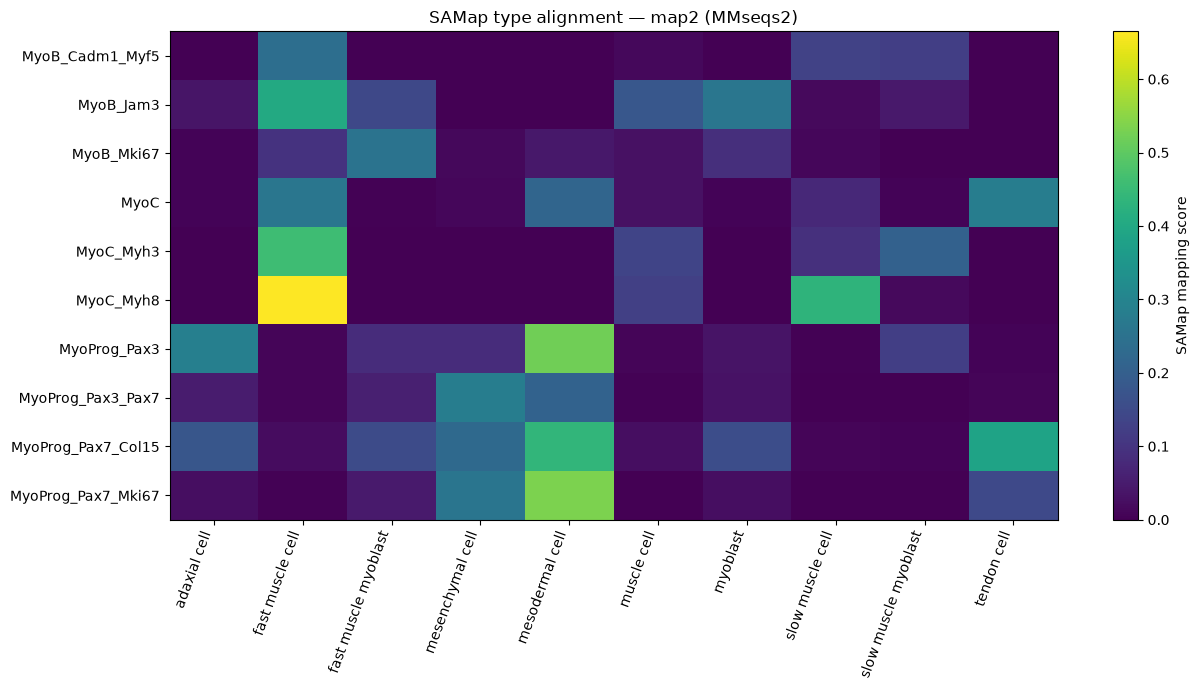

In [4]:
mapping,cross,summary=mapping_context()
print('Full matrix:',mapping.shape,'| mouse:',len(cross.index),'| zebrafish:',len(cross.columns))
display(cross.round(3))
fig,ax=plt.subplots(figsize=(13,7))
im=ax.imshow(cross.values,aspect='auto',interpolation='nearest',vmin=0)
ax.set_xticks(range(len(cross.columns)),[s.removeprefix('dr_') for s in cross.columns],rotation=70,ha='right')
ax.set_yticks(range(len(cross.index)),[s.removeprefix('mm_') for s in cross.index])
ax.set_title('SAMap type alignment — map2 (MMseqs2)')
fig.colorbar(im,ax=ax,label='SAMap mapping score')
fig.tight_layout();plt.show()

## C. Reciprocal best mapping and candidate weakly aligned populations — independent

Score thresholds are exploratory, not measures of homology certainty. The complete cross-species score matrix should also be inspected for plausible one-to-many relationships.

In [5]:
_,cross,summary=mapping_context()
display(summary)
summary.to_csv(OUTPUT_DIR/'map2_type_mapping_summary.csv',index=False)
print('Weak-alignment candidates:',int(summary.candidate_weak_alignment.sum()),
      '| Strong reciprocal references:',int(summary.candidate_reference.sum()))

,species,label,best_partner,best_score,second_score,margin,reciprocal_best,candidate_weak_alignment,candidate_reference,alignment_percentile_within_species,relative_lowest_quartile
0,dr,dr_muscle cell,mm_MyoB_Jam3,0.180948,0.136367,0.044581,False,True,False,0.1,True
1,dr,dr_slow muscle myoblast,mm_MyoC_Myh3,0.205833,0.124212,0.081621,False,True,False,0.2,True
2,dr,dr_fast muscle myoblast,mm_MyoB_Mki67,0.253402,0.153133,0.100269,True,False,False,0.3,False
3,dr,dr_myoblast,mm_MyoB_Jam3,0.261291,0.158377,0.102914,False,False,False,0.4,False
4,dr,dr_mesenchymal cell,mm_MyoProg_Pax3_Pax7,0.283066,0.259280,0.023787,True,False,False,0.5,False
5,dr,dr_adaxial cell,mm_MyoProg_Pax3,0.287606,0.178424,0.109182,False,False,False,0.6,False
6,dr,dr_tendon cell,mm_MyoProg_Pax7_Col15,0.384820,0.281221,0.103600,False,False,False,0.7,False
7,dr,dr_slow muscle cell,mm_MyoC_Myh8,0.431492,0.131941,0.299551,False,False,False,0.8,False
8,dr,dr_mesodermal cell,mm_MyoProg_Pax7_Mki67,0.535181,0.521722,0.013459,True,False,True,0.9,False
9,dr,dr_fast muscle cell,mm_MyoC_Myh8,0.665090,0.458678,0.206413,True,False,True,1.0,False


Weak-alignment candidates: 4 | Strong reciprocal references: 4


## D. GenePairFinder evidence — independent

The table lists gene pairs supporting aligned cell-type programs; it is **not** a complete gene homology map or an exclusivity test. P-values are copied from the SAMap export, not computed here.

In [6]:
gene_pairs=long_gene_pairs(MAP2_GENEPAIRS)
print('Gene-pair entries:',len(gene_pairs),'| cell-type relationships:',gene_pairs.cell_type_pair.nunique())
display(gene_pairs.head(10))
gene_pairs.to_csv(OUTPUT_DIR/'map2_gene_pairs_long.csv',index=False)
for target in ['dr_adaxial cell','dr_slow muscle cell','dr_slow muscle myoblast',
               'dr_fast muscle cell','mm_MyoC_Myh8']:
    subset=gene_pairs[(gene_pairs.dr_cell_type==target)|(gene_pairs.mm_cell_type==target)]
    print(target,':',len(subset),'gene-pair entries')
    display(subset[['cell_type_pair','gene_pair','pval1','pval2','source_rank']].head(8))

Gene-pair entries: 20666 | cell-type relationships: 31


,cell_type_pair,gene_pair,pval1,pval2,dr_gene,mm_gene,dr_cell_type,mm_cell_type,source_rank
0,dr_adaxial cell;mm_MyoProg_Pax3,dr_pcdh8;mm_Fat3,4.653067e-46,0.000000e+00,dr_pcdh8,mm_Fat3,dr_adaxial cell,mm_MyoProg_Pax3,1
1,dr_adaxial cell;mm_MyoProg_Pax3,dr_si:dkey-112m2.1;mm_Tmem132d,4.455085e-09,0.000000e+00,dr_si:dkey-112m2.1,mm_Tmem132d,dr_adaxial cell,mm_MyoProg_Pax3,2
2,dr_adaxial cell;mm_MyoProg_Pax3,dr_adgrl2a;mm_Adgrl2,1.432558e-138,0.000000e+00,dr_adgrl2a,mm_Adgrl2,dr_adaxial cell,mm_MyoProg_Pax3,3
3,dr_adaxial cell;mm_MyoProg_Pax3,dr_epha4a;mm_Epha7,6.619054e-33,0.000000e+00,dr_epha4a,mm_Epha7,dr_adaxial cell,mm_MyoProg_Pax3,4
4,dr_adaxial cell;mm_MyoProg_Pax3,dr_ntn5;mm_Ntn1,1.217166e-13,0.000000e+00,dr_ntn5,mm_Ntn1,dr_adaxial cell,mm_MyoProg_Pax3,5
5,dr_adaxial cell;mm_MyoProg_Pax3,dr_pcdh8;mm_Fat4,4.653067e-46,0.000000e+00,dr_pcdh8,mm_Fat4,dr_adaxial cell,mm_MyoProg_Pax3,6
6,dr_adaxial cell;mm_MyoProg_Pax3,dr_pcdh8;mm_Pcdh15,4.653067e-46,0.000000e+00,dr_pcdh8,mm_Pcdh15,dr_adaxial cell,mm_MyoProg_Pax3,7
7,dr_adaxial cell;mm_MyoProg_Pax3,dr_sema6bb;mm_Sema3d,6.677751e-14,0.000000e+00,dr_sema6bb,mm_Sema3d,dr_adaxial cell,mm_MyoProg_Pax3,8
8,dr_adaxial cell;mm_MyoProg_Pax3,dr_rxraa;mm_Nr2f2,2.560040e-64,1.958413e-169,dr_rxraa,mm_Nr2f2,dr_adaxial cell,mm_MyoProg_Pax3,9
9,dr_adaxial cell;mm_MyoProg_Pax3,dr_LO016987.1;mm_Epha7,4.571306e-04,0.000000e+00,dr_LO016987.1,mm_Epha7,dr_adaxial cell,mm_MyoProg_Pax3,10


dr_adaxial cell : 1381 gene-pair entries


,cell_type_pair,gene_pair,pval1,pval2,source_rank
0,dr_adaxial cell;mm_MyoProg_Pax3,dr_pcdh8;mm_Fat3,4.653067e-46,0.0,1
1,dr_adaxial cell;mm_MyoProg_Pax3,dr_si:dkey-112m2.1;mm_Tmem132d,4.455085e-09,0.0,2
2,dr_adaxial cell;mm_MyoProg_Pax3,dr_adgrl2a;mm_Adgrl2,1.432558e-138,0.0,3
3,dr_adaxial cell;mm_MyoProg_Pax3,dr_epha4a;mm_Epha7,6.619054e-33,0.0,4
4,dr_adaxial cell;mm_MyoProg_Pax3,dr_ntn5;mm_Ntn1,1.217166e-13,0.0,5
5,dr_adaxial cell;mm_MyoProg_Pax3,dr_pcdh8;mm_Fat4,4.653067e-46,0.0,6
6,dr_adaxial cell;mm_MyoProg_Pax3,dr_pcdh8;mm_Pcdh15,4.653067e-46,0.0,7
7,dr_adaxial cell;mm_MyoProg_Pax3,dr_sema6bb;mm_Sema3d,6.677751e-14,0.0,8


dr_slow muscle cell : 1002 gene-pair entries


,cell_type_pair,gene_pair,pval1,pval2,source_rank
15402,dr_slow muscle cell;mm_MyoB_Cadm1_Myf5,dr_clstn1;mm_Clstn2,1.644213e-36,0.000000e+00,1
15403,dr_slow muscle cell;mm_MyoB_Cadm1_Myf5,dr_si:dkey-28i19.1;mm_Prdm1,1.750200e-57,0.000000e+00,2
15404,dr_slow muscle cell;mm_MyoB_Cadm1_Myf5,dr_glra4a;mm_Gabrb2,2.072971e-162,1.561855e-169,3
15405,dr_slow muscle cell;mm_MyoB_Cadm1_Myf5,dr_fgf13a;mm_Fgf6,0.000000e+00,1.392235e-64,4
15406,dr_slow muscle cell;mm_MyoB_Cadm1_Myf5,dr_mef2aa;mm_Mef2c,0.000000e+00,0.000000e+00,5
15407,dr_slow muscle cell;mm_MyoB_Cadm1_Myf5,dr_fgf13a;mm_Fgf14,0.000000e+00,6.114967e-193,6
15408,dr_slow muscle cell;mm_MyoB_Cadm1_Myf5,dr_nectin3b;mm_Nectin3,1.334358e-226,0.000000e+00,7
15409,dr_slow muscle cell;mm_MyoB_Cadm1_Myf5,dr_fgf11a;mm_Fgf6,4.268672e-85,1.392235e-64,8


... (2 outputs left out)

dr_fast muscle cell : 1572 gene-pair entries


,cell_type_pair,gene_pair,pval1,pval2,source_rank
1381,dr_fast muscle cell;mm_MyoB_Cadm1_Myf5,dr_palld;mm_Palld,3.616153e-93,0.0,1
1382,dr_fast muscle cell;mm_MyoB_Cadm1_Myf5,dr_ptprua;mm_Ptprt,6.362207e-139,0.0,2
1383,dr_fast muscle cell;mm_MyoB_Cadm1_Myf5,dr_mef2ca;mm_Mef2c,1.177784e-31,0.0,3
1384,dr_fast muscle cell;mm_MyoB_Cadm1_Myf5,dr_mef2cb;mm_Mef2c,4.644306e-286,0.0,4
1385,dr_fast muscle cell;mm_MyoB_Cadm1_Myf5,dr_ptprua;mm_Ptprk,6.362207e-139,0.0,5
1386,dr_fast muscle cell;mm_MyoB_Cadm1_Myf5,dr_myo16;mm_Myo16,6.082417e-06,0.0,6
1387,dr_fast muscle cell;mm_MyoB_Cadm1_Myf5,dr_ctnna2;mm_Ctnna2,0.000000e+00,0.0,7
1388,dr_fast muscle cell;mm_MyoB_Cadm1_Myf5,dr_epha3;mm_Epha7,4.450550e-26,0.0,8


mm_MyoC_Myh8 : 1396 gene-pair entries


,cell_type_pair,gene_pair,pval1,pval2,source_rank
2529,dr_fast muscle cell;mm_MyoC_Myh8,dr_myhz1.1__ENSDARG00000067990;mm_Myh8,0.0,0.0,1
2530,dr_fast muscle cell;mm_MyoC_Myh8,dr_tnnt3b;mm_Tnnt3,0.0,0.0,2
2531,dr_fast muscle cell;mm_MyoC_Myh8,dr_myhz1.3;mm_Myh8,0.0,0.0,3
2532,dr_fast muscle cell;mm_MyoC_Myh8,dr_tnnt3a;mm_Tnnt3,0.0,0.0,4
2533,dr_fast muscle cell;mm_MyoC_Myh8,dr_ryr3;mm_Ryr3,0.0,0.0,5
2534,dr_fast muscle cell;mm_MyoC_Myh8,dr_myhz1.2;mm_Myh8,0.0,0.0,6
2535,dr_fast muscle cell;mm_MyoC_Myh8,dr_tnni2a.4;mm_Tnni2,0.0,0.0,7
2536,dr_fast muscle cell;mm_MyoC_Myh8,dr_mylz3;mm_Myl1,0.0,0.0,8


## E. Read-only H5AD inspection — independent

Inspect existing Scanpy metadata, embeddings and layers without loading the full expression matrix. Each independent H5AD section opens and closes its own read-only file handle.

In [7]:
with open_map2_h5ad() as adata:
    print('AnnData shape:',adata.shape,'| backed:',adata.isbacked)
    for name in ['obs','var','obsm','obsp','layers','uns']:
        value=getattr(adata,name)
        print(name,'keys:',list(value.columns)[:30] if name in ['obs','var'] else list(value.keys())[:30])
    for key in adata.obsm:
        print('obsm',key,'shape:',adata.obsm[key].shape)
    print('Raw available:',adata.raw is not None)

AnnData shape: (20000, 77556) | backed: True
obs keys: ['mm_donor_id', 'mm_development_stage_ontology_term_id', 'mm_sex_ontology_term_id', 'mm_self_reported_ethnicity_ontology_term_id', 'mm_disease_ontology_term_id', 'mm_tissue_ontology_term_id', 'mm_cell_type_ontology_term_id', 'mm_assay_ontology_term_id', 'mm_suspension_type', 'mm_author_experimental_id', 'mm_author_day', 'mm_author_somite_count', 'mm_author_major_cell_cluster', 'mm_author_cell_type', 'mm_tissue_type', 'mm_cell_type_origin', 'mm_assay', 'mm_disease', 'mm_sex', 'mm_tissue', 'mm_self_reported_ethnicity', 'mm_development_stage', 'mm_leiden_re_0.3', 'mm_leiden_re_0.6', 'mm_leiden_re_0.4', 'mm_leiden_re_1', 'mm_cell_type', 'mm_leiden_clusters', 'dr_projection_group', 'dr_cell_type_long']
var keys: []
obsm keys: ['X_umap']
obsp keys: ['connectivities']
layers keys: ['X_disp']
uns keys: ['dr_cell_type_colors', 'gnnm_corr', 'homology_gene_names_dict', 'mapping_K', 'mm_cell_type_colors', 'neighbors', 'species_colors', 'umap']

## F. Species and cell-type metadata — independent

Annotate cells using the original SAMap `.obs` columns and independently read mapping strengths. Missing/unknown labels raise errors instead of silently flowing into LOF.

In [8]:
with open_map2_h5ad() as adata:
    info=infer_cell_info(adata)
print('Species counts:');display(info.species.value_counts())
display(info.groupby(['species','label']).size().rename('n_cells').reset_index())

Species counts:


species
mm    15161
dr     4839
Name: count, dtype: int64

,species,label,n_cells
0,dr,dr_adaxial cell,9
1,dr,dr_fast muscle cell,2767
2,dr,dr_fast muscle myoblast,60
3,dr,dr_mesenchymal cell,85
4,dr,dr_mesodermal cell,586
5,dr,dr_muscle cell,162
6,dr,dr_myoblast,51
7,dr,dr_slow muscle cell,912
8,dr,dr_slow muscle myoblast,124
9,dr,dr_tendon cell,83


## G. Existing Scanpy joint UMAP and optional stored-graph diagnostic — independent

`adata.obsm['X_umap']` contains the **existing mouse–zebrafish joint 2D projection**. This section visualizes it. **H1/H2/H3 now also use these same stored coordinates for exploratory nearest-neighbor/density calculations.** UMAP's displayed distances are not guaranteed to represent original high-dimensional expression distances; any cluster separation must be checked against upstream SAMap outputs. The optional graph diagnostic still describes only the saved H5AD subset.


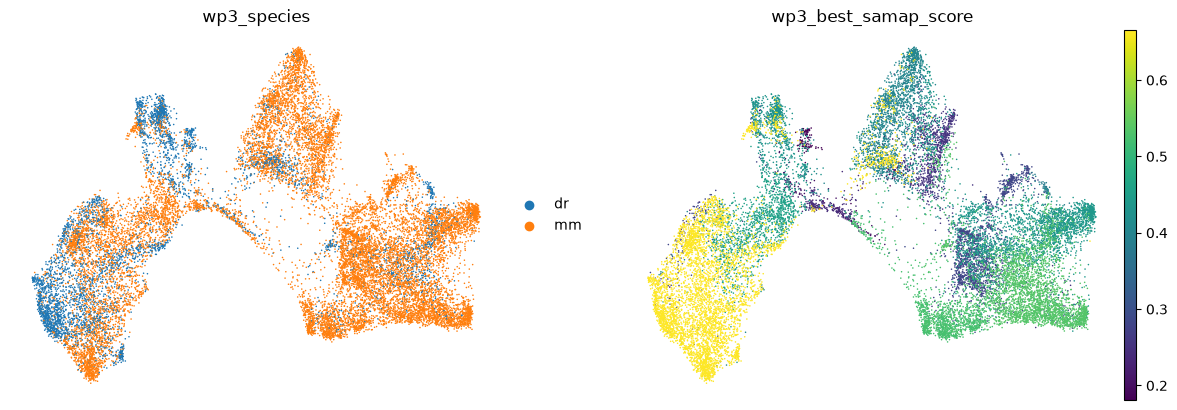

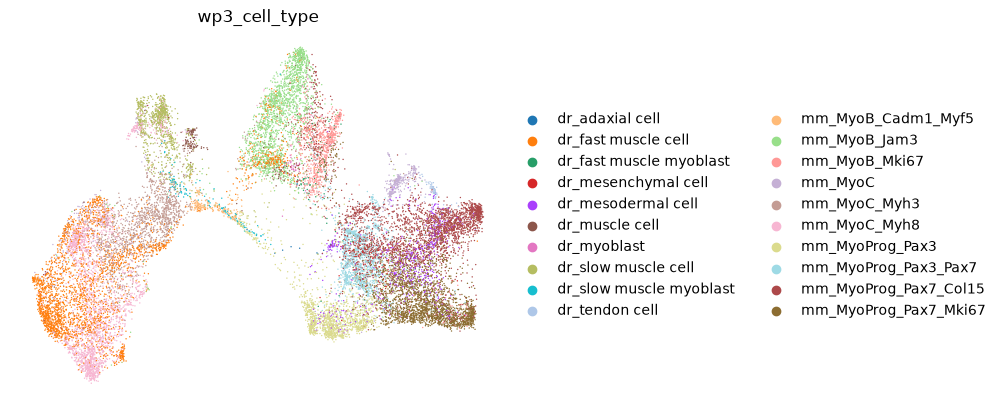

Rows with zero retained connectivity: 2592


label
dr_myoblast                0.452661
mm_MyoProg_Pax7_Mki67      0.511871
dr_muscle cell             0.515303
mm_MyoProg_Pax3_Pax7       0.519485
mm_MyoB_Mki67              0.527670
dr_fast muscle myoblast    0.530055
mm_MyoC_Myh3               0.558667
dr_adaxial cell            0.561202
mm_MyoProg_Pax7_Col15      0.570512
mm_MyoC                    0.574561
dr_slow muscle cell        0.586101
mm_MyoC_Myh8               0.613727
mm_MyoB_Cadm1_Myf5         0.617557
mm_MyoB_Jam3               0.619188
dr_slow muscle myoblast    0.625307
dr_fast muscle cell        0.631741
dr_mesodermal cell         0.633284
mm_MyoProg_Pax3            0.657426
dr_mesenchymal cell        0.706415
dr_tendon cell             0.772805
Name: cross_species_graph_fraction, dtype: float64

In [9]:
with open_map2_h5ad() as adata:
    info=infer_cell_info(adata)
    if 'X_umap' in adata.obsm:
        adata.obs['wp3_species']=pd.Categorical(info.species.to_numpy())
        adata.obs['wp3_best_samap_score']=info.best_score.to_numpy(dtype=float)
        adata.obs['wp3_cell_type']=pd.Categorical(info.label.to_numpy())
        sc.pl.umap(adata,color=['wp3_species','wp3_best_samap_score'],ncols=2,
                   size=5,frameon=False,show=False)
        plt.show()
        sc.pl.umap(adata,color='wp3_cell_type',size=4,legend_loc='right margin',
                   frameon=False,show=False)
        plt.show()
    else: print('No stored UMAP; no projection recomputed.')
    if 'connectivities' in adata.obsp:
        graph=adata.obsp['connectivities']
        graph=graph.tocsr() if sp.issparse(graph) else sp.csr_matrix(graph)
        if graph.shape==(adata.n_obs,adata.n_obs):
            source_rows=np.repeat(np.arange(graph.shape[0]),np.diff(graph.indptr))
            species=info.species.to_numpy()
            total=np.bincount(source_rows,weights=graph.data,minlength=len(info))
            cross=np.bincount(source_rows,weights=graph.data*(species[source_rows]!=species[graph.indices]),minlength=len(info))
            info['cross_species_graph_fraction']=np.divide(cross,total,
                out=np.full(len(info),np.nan),where=total>0)
            print('Rows with zero retained connectivity:',int((total==0).sum()))
            display(info.groupby('label').cross_species_graph_fraction.mean().sort_values().head(20))

## H. Joint-UMAP preflight (optional; independent)

Verify that both species appear in the same stored `X_umap` coordinate array, that the coordinates are finite and variable, and that the H5AD cell-row alignment matches metadata. This diagnostic is optional: H1 and H2 independently call the same loader. **There is no high-dimensional embedding prerequisite for this exploratory joint-UMAP run.**


In [10]:
with open_map2_h5ad() as adata:
    print('Available .obsm:',{k:getattr(v,'shape',None) for k,v in adata.obsm.items()})
    print('External joint NPZ override:',JOINT_EMBEDDING_NPZ)
    print('Selected shared obsm key:',JOINT_EMBEDDING_OBSM_KEY)
    print('Coordinate scaling:',JOINT_COORDINATE_SCALING)
    try:
        prepared,source=load_joint_embedding(adata)
    except (ValueError,FileNotFoundError,KeyError) as exc:
        print('Joint coordinates NOT READY:',exc)
    else:
        print('Joint coordinate shape:',prepared.shape,'provenance:',source)
        species=infer_cell_info(adata).species.value_counts().to_dict()
        print('Species represented:',species)
        print('Near-zero variance dimensions:',int((prepared.var(axis=0)<1e-14).sum()))
        print('REMINDER: UMAP 2D local distances/densities can be distorted relative to the original SAMap latent space.')

Available .obsm: {'X_umap': (20000, 2)}
External joint NPZ override: None
Selected shared obsm key: X_umap
Coordinate scaling: none
EXPLORATORY INPUT: stored joint 2D UMAP shape: (20000, 2) | distances/densities may differ from original high-dimensional SAMap space
Joint coordinate shape: (20000, 2) provenance: {'source': 'obsm', 'key': 'X_umap', 'exploratory_only': True, 'coordinates': 'stored joint 2D UMAP', 'dimensions': [20000, 2], 'h5ad': {'path': '/home/giatraskon/Desktop/Repositories & Projects/BioHackEU2026/samap_mm_dr_map2_20K.h5ad', 'size': 109204821, 'mtime_ns': 1794241394000000000}, 'coordinate_scaling': 'none'}
Species represented: {'mm': 15161, 'dr': 4839}
Near-zero variance dimensions: 0
REMINDER: UMAP 2D local distances/densities can be distorted relative to the original SAMap latent space.


/tmp/ipykernel_45655/1148732249.py:157: UserWarning: Running both species-aware LOF methods on stored joint 2D UMAP. UMAP does not preserve all original distances/densities; interpret as exploratory.
  warnings.warn('Running both species-aware LOF methods on stored joint 2D UMAP. '


## H0. Historical within-species anomaly baseline (optional; independent)

This preserves the earlier Isolation Forest, ordinary `LOF(novelty=False)`, and reference-based One-Class SVM experiment **for comparison only**. It does not measure cross-species novelty. Disabled by default: set `RUN_LEGACY_NOVELTY=True` in Setup 2 and provide a suitable joint embedding to reproduce it.

In [11]:
if not RUN_LEGACY_NOVELTY:
    print('Historical within-species baseline disabled; continue with H1/H2.')
else:
    E,info,provenance=get_joint_context()
    local_rng=np.random.default_rng(SEED+10)
    groups=list(info.groupby(['species','label'],sort=True).indices.values())
    quota=max(15,int(MAX_CELLS_FOR_NOVELTY/max(1,len(groups))))
    indices=np.unique(np.concatenate([local_rng.choice(v,min(len(v),quota),replace=False)
                                       for v in groups if len(v)]))
    if len(indices)>MAX_CELLS_FOR_NOVELTY:
        indices=np.sort(local_rng.choice(indices,MAX_CELLS_FOR_NOVELTY,replace=False))
    sub=info.iloc[indices].copy().reset_index(drop=True)
    features=E[indices]
    for col in ['isoforest_anomaly','lof_anomaly','ocsvm_anomaly']:
        sub[col]=np.nan
    for sid in ['mm','dr']:
        loc=np.flatnonzero(sub.species.to_numpy()==sid)
        if len(loc)<35:continue
        Z=StandardScaler().fit_transform(features[loc])
        iso=IsolationForest(n_estimators=150,random_state=SEED,n_jobs=-1)
        iso.fit(Z)
        sub.loc[loc,'isoforest_anomaly']=-iso.score_samples(Z)
        lof=LocalOutlierFactor(n_neighbors=min(30,len(loc)-1),novelty=False,n_jobs=-1)
        lof.fit(Z)
        sub.loc[loc,'lof_anomaly']=-lof.negative_outlier_factor_
    ref=np.flatnonzero(sub.candidate_reference.fillna(False).astype(bool).to_numpy())
    if len(ref)>=100 and len(set(sub.species.iloc[ref]))==2:
        selected=[]
        for sid in ['mm','dr']:
            candidates=ref[(sub.species.iloc[ref]==sid).to_numpy()]
            selected.append(local_rng.choice(candidates,min(len(candidates),MAX_OCSVM_REFERENCE//2),replace=False))
        train=np.concatenate(selected)
        scaler=StandardScaler().fit(features[train])
        ocsvm=OneClassSVM(kernel='rbf',nu=.05,gamma='scale',cache_size=300)
        ocsvm.fit(scaler.transform(features[train]))
        sub['ocsvm_anomaly']=-ocsvm.decision_function(scaler.transform(features))
        sub['ocsvm_was_training_cell']=False
        sub.loc[train,'ocsvm_was_training_cell']=True
    for name in ['isoforest_anomaly','lof_anomaly','ocsvm_anomaly']:
        sub[name+'_percentile']=sub.groupby('species')[name].rank(pct=True)
    ranks=[name+'_percentile' for name in ['isoforest_anomaly','lof_anomaly','ocsvm_anomaly']]
    sub['mean_anomaly_percentile']=sub[ranks].mean(axis=1)
    sub.to_csv(OUTPUT_DIR/'map2_cell_novelty_scores.csv',index=False)
    types=sub.groupby(['species','label'],as_index=False).agg(
        cells=('cell_id','size'),best_alignment=('best_score','first'),
        mean_anomaly=('mean_anomaly_percentile','mean'),
        median_anomaly=('mean_anomaly_percentile','median'))
    types.to_csv(OUTPUT_DIR/'map2_method_comparison_by_cell_type.csv',index=False)
    display(types.sort_values('median_anomaly',ascending=False).head(20))
    print('Historical baseline provenance:',provenance)

Historical within-species baseline disabled; continue with H1/H2.


## H1. Directional cross-species LOF — **classical LOF in novelty mode** (independent)

**Scientific question:** Is a target cell locally sparse relative to the *other species' reference distribution* in the **shared stored 2D SAMap UMAP projection**?

For each direction (`mm` reference → `dr` target, then reverse):

1. Set aside *held-out* reference-species cells (never used for fitting); cap the fitting sample at `CROSS_LOF_REFERENCE_TRAIN_MAX`.
2. Fit a `StandardScaler` **only** on reference training cells and a `LocalOutlierFactor(novelty=True, n_neighbors=k)` on those cells.
3. Evaluate the target species and **unseen** held-out reference cells with `-lof.score_samples`, so *higher = more anomalous*.
4. Calibrate the target scores using the observed **held-out reference** distribution. Report both the empirical reference percentile and the fraction exceeding its 95th percentile (configurable).
5. Aggregate **after** cell-level scoring by annotation. Controls are saved separately from scored target cells.

**Interpretation:** An entire coherent zebrafish cluster can be unusual compared with the mouse reference, but this does not prove absence of a homolog. Cross-direction **raw** LOF values are not directly comparable; reference-calibrated percentiles are more interpretable. Reference sampling and developmental-stage mismatch remain confounders. The held-out reference quantile is a descriptive baseline, **not a calibrated hypothesis-test p-value**.

Scikit-learn: <https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.LocalOutlierFactor.html>. For `novelty=True`, **never call `score_samples()` on the training cells**.
**Geometry:** The default uses unscaled UMAP coordinates, retaining their original Euclidean geometry; 2D UMAP density/spacing can be strongly distorted. This run is an exploratory screen, not validated evolutionary novelty.


In [12]:
def directional_cross_species_lof(X, info, k=30, seed=42,
        train_cap=3000, control_cap=1000, control_fraction=.25,
        quantile=.95, max_targets=None, scaling='none'):
    """Score each species against unseen-reference LOF for the opposite species.

    X: VALIDATED joint coordinates (n_cells, n_features).
    info: species, label and cell_id in exactly the same row order as X.
    Returns (target_cell_scores, heldout_reference_scores, type_summary, diagnostics).
    """
    if len(X)!=len(info) or not np.isfinite(X).all():
        raise ValueError('X/info row mismatch or nonfinite joint coordinates')
    out, controls, diagnostics = [], [], []
    species=info.species.to_numpy()
    for direction,(ref_sid,target_sid) in enumerate([('mm','dr'),('dr','mm')]):
        rng=np.random.default_rng(seed+100+direction)
        ref=np.flatnonzero(species==ref_sid)
        target=np.flatnonzero(species==target_sid)
        if len(ref)<k+40 or len(target)==0:
            print('SKIP',ref_sid,'→',target_sid,': insufficient reference/target observations')
            continue
        # Keep control samples separate from reference training cells.
        nctrl=min(control_cap,max(k+10,int(round(len(ref)*control_fraction))))
        nctrl=min(nctrl,len(ref)-(k+2))
        heldout=np.sort(rng.choice(ref,size=nctrl,replace=False))
        remaining=np.setdiff1d(ref,heldout,assume_unique=True)
        train=np.sort(rng.choice(remaining,size=min(len(remaining),train_cap),replace=False))
        if max_targets is not None and len(target)>max_targets:
            # Uniform target sampling: does not silently stratify/dilute densities.
            target=np.sort(rng.choice(target,size=max_targets,replace=False))
        if scaling=='none':
            train_z,ctrl_z,tgt_z=X[train],X[heldout],X[target]
        elif scaling=='standard':
            scaler=StandardScaler().fit(X[train])
            train_z=scaler.transform(X[train])
            ctrl_z=scaler.transform(X[heldout])
            tgt_z=scaler.transform(X[target])
        else:
            raise ValueError('scaling must be "none" or "standard"')
        model=LocalOutlierFactor(n_neighbors=min(k,len(train)-1),
                                 novelty=True, contamination='auto',n_jobs=-1)
        model.fit(train_z)
        # Controls and targets are strictly disjoint from the fitted reference.
        ctrl_scores=-model.score_samples(ctrl_z)
        tgt_scores=-model.score_samples(tgt_z)
        cutoff=float(np.quantile(ctrl_scores,quantile))
        ordered=np.sort(ctrl_scores)
        # Midrank for exact score ties; reference percentiles are descriptive.
        pct=(np.searchsorted(ordered,tgt_scores,'left')+
             np.searchsorted(ordered,tgt_scores,'right'))/(2*len(ordered))
        direction_name=f'{ref_sid}_reference_to_{target_sid}'
        tgt=info.iloc[target].copy().reset_index(drop=True)
        tgt['reference_species']=ref_sid
        tgt['direction']=direction_name
        tgt['cross_species_lof']=tgt_scores
        tgt['reference_percentile']=pct
        tgt['above_reference_quantile']=tgt_scores>cutoff
        tgt['reference_threshold']=cutoff
        out.append(tgt)
        control=info.iloc[heldout][['cell_id','species','label']].copy().reset_index(drop=True)
        control['direction']=direction_name
        control['reference_lof']=ctrl_scores
        control['reference_threshold']=cutoff
        controls.append(control)
        diagnostics.append({'direction':direction_name,'n_reference_train':len(train),
            'n_reference_holdout':len(heldout),'n_target':len(target),'k':model.n_neighbors_,
            'reference_score_95th_or_configured':cutoff,
            'reference_heldout_fraction_above':float(np.mean(ctrl_scores>cutoff)),
            'target_fraction_above':float(np.mean(tgt_scores>cutoff))})
    if not out:raise ValueError('No directional LOF fits possible')
    cells=pd.concat(out,ignore_index=True)
    controls=pd.concat(controls,ignore_index=True)
    types=(cells.groupby(['species','label','direction'],as_index=False)
        .agg(cells=('cell_id','size'),reference_species=('reference_species','first'),
             best_alignment=('best_score','first'),
             reciprocal_best=('reciprocal_best','first'),
             median_cross_species_lof=('cross_species_lof','median'),
             median_reference_percentile=('reference_percentile','median'),
             mean_reference_percentile=('reference_percentile','mean'),
             fraction_above_reference_quantile=('above_reference_quantile','mean')))
    return cells,controls,types,diagnostics


try:
    E,info,provenance=get_joint_context()
except (FileNotFoundError,ValueError,KeyError) as exc:
    print('H1 not run:',exc)
else:
    cells,controls,types,diagnostics=directional_cross_species_lof(
        E,info,k=CROSS_LOF_K,seed=SEED,
        train_cap=CROSS_LOF_REFERENCE_TRAIN_MAX,
        control_cap=CROSS_LOF_REFERENCE_CONTROL_MAX,
        control_fraction=CROSS_LOF_CONTROL_FRACTION,
        quantile=CROSS_LOF_REFERENCE_QUANTILE,
        max_targets=CROSS_LOF_MAX_TARGET_CELLS,
        scaling=JOINT_COORDINATE_SCALING)
    params=dict(k=CROSS_LOF_K,reference_train_max=CROSS_LOF_REFERENCE_TRAIN_MAX,
                reference_control_max=CROSS_LOF_REFERENCE_CONTROL_MAX,
                reference_quantile=CROSS_LOF_REFERENCE_QUANTILE,
                sampling='uniform reference/target; controls strictly held out',
                coordinate_scaling=JOINT_COORDINATE_SCALING,
                direction_diagnostics=diagnostics)
    save_analysis('map2_cross_species_lof',cells,types,params,provenance)
    controls.to_csv(OUTPUT_DIR/'map2_cross_species_lof_controls.csv',index=False)
    display(pd.DataFrame(diagnostics))
    display(types.sort_values('median_reference_percentile',ascending=False).head(25))
    print('NOTE: based on 2D UMAP; cross-species LOF is exploratory, NOT proof of non-homology')

/tmp/ipykernel_45655/1148732249.py:157: UserWarning: Running both species-aware LOF methods on stored joint 2D UMAP. UMAP does not preserve all original distances/densities; interpret as exploratory.
  warnings.warn('Running both species-aware LOF methods on stored joint 2D UMAP. '


EXPLORATORY INPUT: stored joint 2D UMAP shape: (20000, 2) | distances/densities may differ from original high-dimensional SAMap space
Saved: /home/giatraskon/Desktop/Repositories & Projects/BioHackEU2026/wp3_results/map2_cross_species_lof_cells.csv and type/metadata files


,direction,n_reference_train,n_reference_holdout,n_target,k,reference_score_95th_or_configured,reference_heldout_fraction_above,target_fraction_above
0,mm_reference_to_dr,3000,1000,4839,30,1.280841,0.05,0.211821
1,dr_reference_to_mm,3000,1000,15161,30,1.373693,0.05,0.258492


,species,label,direction,cells,reference_species,best_alignment,reciprocal_best,median_cross_species_lof,median_reference_percentile,mean_reference_percentile,fraction_above_reference_quantile
13,mm,mm_MyoC,dr_reference_to_mm,531,dr,0.281221,False,1.894055,0.9900,0.777088,0.548023
0,dr,dr_adaxial cell,mm_reference_to_dr,9,mm,0.287606,False,1.560123,0.9850,0.953778,0.888889
9,dr,dr_tendon cell,mm_reference_to_dr,83,mm,0.384820,False,1.426495,0.9710,0.844663,0.566265
5,dr,dr_muscle cell,mm_reference_to_dr,162,mm,0.180948,False,1.294980,0.9525,0.767654,0.530864
19,mm,mm_MyoProg_Pax7_Mki67,dr_reference_to_mm,2434,dr,0.535181,True,1.313616,0.9330,0.803797,0.431800
12,mm,mm_MyoB_Mki67,dr_reference_to_mm,778,dr,0.253402,True,1.263232,0.9070,0.890568,0.170951
18,mm,mm_MyoProg_Pax7_Col15,dr_reference_to_mm,2932,dr,0.438527,False,1.249676,0.9010,0.785422,0.361869
14,mm,mm_MyoC_Myh3,dr_reference_to_mm,1386,dr,0.458678,False,1.211972,0.8830,0.762056,0.256133
1,dr,dr_fast muscle cell,mm_reference_to_dr,2767,mm,0.665090,True,1.112351,0.8340,0.698922,0.263462
8,dr,dr_slow muscle myoblast,mm_reference_to_dr,124,mm,0.205833,False,1.104360,0.8115,0.642738,0.088710


NOTE: based on 2D UMAP; cross-species LOF is exploratory, NOT proof of non-homology


## H2. Species-aware joint-neighborhood separation — **not classical LOF** (independent)

**Scientific question:** Is a cell surrounded by a **coherent neighborhood of its own species** while its kth nearest cells from the other species are substantially farther away?

**Algorithm:** Uniformly sample the same number of *reference-bank* cells from both species (to counter cell-count imbalance). By default use the stored UMAP coordinates **without per-axis scaling**; optional shared z-scoring can be used for sensitivity analysis. For every original query cell, compute:

\[
 S_i = \log\left(\frac{d_{k,\mathrm{other}}(i)+\epsilon}{d_{k,\mathrm{same}}(i)+\epsilon}\right)
\]

- `d_same`: distance to the kth nearest *same*-species **bank** cell (excluding the query itself if it was sampled into its bank).
- `d_other`: distance to the kth nearest *other*-species bank cell.
- **Positive** S: other-species neighbors are farther than same-species neighbors; larger values indicate stronger *relative local species separation*.
- **Near zero** S: similar kth-neighbor distances; **negative** S: other-species neighborhood is closer on this scale.
- We also report the fraction of the pooled 2k nearest bank neighbors belonging to the other species (`cross_species_fraction_2k`), which is a descriptive **species mixing** statistic, not LOF.

Species-balanced banks reduce count bias but do not remove unequal cell-state coverage or technical batch effects. A high score can reflect integration failure, missing comparison states, different developmental stages, or genuine divergence. The per-species upper-decile flag is **rank-based by construction**, not a p-value.
**Geometry:** The metric uses the 2D joint UMAP directly, not the original high-dimensional SAMap coordinates. UMAP can distort relative cluster densities and Euclidean distances; report this as *UMAP-based species separation* and test robustness before biological interpretation.


/tmp/ipykernel_45655/1148732249.py:157: UserWarning: Running both species-aware LOF methods on stored joint 2D UMAP. UMAP does not preserve all original distances/densities; interpret as exploratory.
  warnings.warn('Running both species-aware LOF methods on stored joint 2D UMAP. '


EXPLORATORY INPUT: stored joint 2D UMAP shape: (20000, 2) | distances/densities may differ from original high-dimensional SAMap space
Saved: /home/giatraskon/Desktop/Repositories & Projects/BioHackEU2026/wp3_results/map2_species_separation_cells.csv and type/metadata files
Diagnostics: {'bank_size_per_species': 3000, 'k': 30, 'mean_log_separation_by_species': {'dr': 0.7778198269851698, 'mm': 0.581175322979433}, 'fraction_positive_by_species': {'dr': 0.8080181855755322, 'mm': 0.7827979684717367}, 'num_nearly_zero_same_distances': 0, 'coordinate_scaling': 'none'}


,species,label,cells,best_alignment,reciprocal_best,median_log_separation,mean_log_separation,fraction_positive,fraction_top_quantile,median_cross_species_fraction_2k
7,dr,dr_slow muscle cell,912,0.431492,False,1.557664,1.516178,0.975877,0.220395,0.050000
5,dr,dr_muscle cell,162,0.180948,False,1.471786,1.137099,0.950617,0.000000,0.116667
16,mm,mm_MyoProg_Pax3,1440,0.521722,False,1.093214,0.981569,0.906944,0.159028,0.166667
12,mm,mm_MyoB_Mki67,778,0.253402,True,1.033009,0.953634,0.962725,0.110540,0.133333
19,mm,mm_MyoProg_Pax7_Mki67,2434,0.535181,True,0.993439,0.954192,0.948644,0.199260,0.100000
17,mm,mm_MyoProg_Pax3_Pax7,1251,0.283066,True,0.959240,0.894155,0.988010,0.000799,0.116667
9,dr,dr_tendon cell,83,0.384820,False,0.934841,0.583261,0.771084,0.000000,0.216667
18,mm,mm_MyoProg_Pax7_Col15,2932,0.438527,False,0.754162,0.762238,0.891542,0.136085,0.166667
1,dr,dr_fast muscle cell,2767,0.665090,True,0.660906,0.856118,0.887965,0.102277,0.216667
13,mm,mm_MyoC,531,0.281221,False,0.598648,0.367659,0.629002,0.163842,0.166667


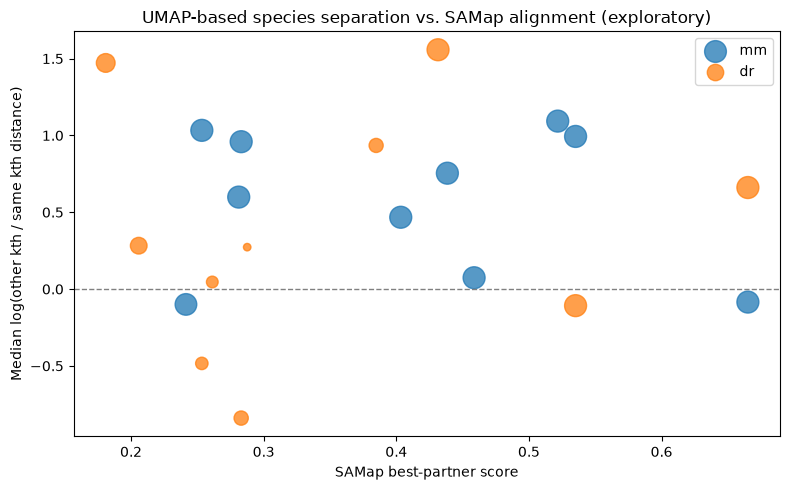

In [13]:
def kth_bank_distances(X, query_idx, bank_idx, k, exclude_self):
    """Return kth Euclidean distance for each query, using bank global indices.
    Excludes the query itself when it belongs to its reference bank.
    """
    bank_idx=np.asarray(bank_idx,dtype=int)
    query_idx=np.asarray(query_idx,dtype=int)
    required=k+1 if exclude_self else k
    if len(bank_idx)<required:
        raise ValueError(f'Bank has {len(bank_idx)} samples, needs >= {required}')
    nbrs=NearestNeighbors(n_neighbors=required,n_jobs=-1).fit(X[bank_idx])
    dist,local=nbrs.kneighbors(X[query_idx],return_distance=True)
    if exclude_self:
        matches=bank_idx[local]==query_idx[:,None]
        # Keep kth neighbor after discarding self; for nonbank queries the first k are used.
        dist=np.where(matches,np.inf,dist)
    return np.partition(dist,k-1,axis=1)[:,k-1]


def balanced_species_separation(X,info,k=30,bank_cap=3000,seed=42,top_quantile=.90,scaling='none'):
    """Species-aware cross/within kth-distance ratio using equal-sized species banks.
    This is NOT the classic LOF algorithm.
    """
    if len(X)!=len(info) or not np.isfinite(X).all():
        raise ValueError('Joint coordinates and cell_info must align and be finite')
    species=info.species.to_numpy()
    Z,indices,banks,size=balanced_joint_coordinates(X,info,bank_cap=bank_cap,seed=seed,scaling=scaling)
    if size<=k+1:raise ValueError('Not enough cells in balanced banks for k neighbors')
    rows=[]
    for sid,other in [('mm','dr'),('dr','mm')]:
        query=indices[sid]
        ds=kth_bank_distances(Z,query,banks[sid],k,exclude_self=True)
        do=kth_bank_distances(Z,query,banks[other],k,exclude_self=False)
        # Relative scale: epsilon should remain tiny compared with nonzero neighbor distances.
        positive=np.r_[ds[ds>0],do[do>0]]
        eps=max(1e-12,1e-8*float(np.median(positive))) if positive.size else 1e-12
        score=np.log((do+eps)/(ds+eps))
        # A *pooled* neighborhood mixing diagnostic on the same equal-sized banks.
        pool=np.r_[banks['mm'],banks['dr']]
        n_pool=min(2*k+1,len(pool))
        knn=NearestNeighbors(n_neighbors=n_pool,n_jobs=-1).fit(Z[pool])
        dist,which=knn.kneighbors(Z[query])
        global_neighbors=pool[which]
        is_self=global_neighbors==query[:,None]
        d_for_rank=np.where(is_self,np.inf,dist)
        take=np.argsort(d_for_rank,axis=1)[:,:min(2*k,len(pool)-1)]
        chosen=np.take_along_axis(global_neighbors,take,axis=1)
        crossfrac=(species[chosen]!=sid).mean(axis=1)
        part=info.iloc[query].copy().reset_index(drop=True)
        part['same_species_k_distance']=ds
        part['other_species_k_distance']=do
        part['log_other_over_same_kdist']=score
        part['cross_species_fraction_2k']=crossfrac
        part['bank_size_per_species']=size
        part['k']=k
        rows.append(part)
    cells=pd.concat(rows,ignore_index=True)
    cells['separation_percentile_within_species']=cells.groupby('species')['log_other_over_same_kdist'].rank(pct=True)
    cells['above_species_top_quantile']=(
        cells.groupby('species')['log_other_over_same_kdist']
             .transform(lambda s:s > s.quantile(top_quantile)))
    cells['positive_species_separation']=cells.log_other_over_same_kdist>0
    types=(cells.groupby(['species','label'],as_index=False).agg(
        cells=('cell_id','size'),best_alignment=('best_score','first'),
        reciprocal_best=('reciprocal_best','first'),
        median_log_separation=('log_other_over_same_kdist','median'),
        mean_log_separation=('log_other_over_same_kdist','mean'),
        fraction_positive=('positive_species_separation','mean'),
        fraction_top_quantile=('above_species_top_quantile','mean'),
        median_cross_species_fraction_2k=('cross_species_fraction_2k','median')))
    diagnostics={'bank_size_per_species':size,'k':k,
        'mean_log_separation_by_species':cells.groupby('species').log_other_over_same_kdist.mean().to_dict(),
        'fraction_positive_by_species':cells.groupby('species').positive_species_separation.mean().to_dict(),
        'num_nearly_zero_same_distances':int((cells.same_species_k_distance<1e-10).sum()),
        'coordinate_scaling':scaling}
    return cells,types,diagnostics


try:
    E,info,provenance=get_joint_context()
except (FileNotFoundError,ValueError,KeyError) as exc:
    print('H2 not run:',exc)
else:
    cells,types,diagnostics=balanced_species_separation(
        E,info,k=SEPARATION_K,bank_cap=SEPARATION_BANK_MAX_PER_SPECIES,
        seed=SEED,top_quantile=SEPARATION_TOP_QUANTILE,scaling=JOINT_COORDINATE_SCALING)
    params=dict(k=SEPARATION_K,bank_max=SEPARATION_BANK_MAX_PER_SPECIES,
                top_quantile=SEPARATION_TOP_QUANTILE,
                reference_banks='uniform equal size by species, self-excluded',
                coordinate_scaling=JOINT_COORDINATE_SCALING,diagnostics=diagnostics)
    save_analysis('map2_species_separation',cells,types,params,provenance)
    print('Diagnostics:',diagnostics)
    display(types.sort_values('median_log_separation',ascending=False).head(25))
    fig,ax=plt.subplots(figsize=(8,5))
    for sid in ['mm','dr']:
        z=types[types.species==sid]
        ax.scatter(z.best_alignment,z.median_log_separation,s=np.minimum(250,20+z.cells),
                   alpha=.75,label=sid)
    ax.axhline(0,color='gray',linestyle='--',linewidth=1)
    ax.set(xlabel='SAMap best-partner score',ylabel='Median log(other kth / same kth distance)',
           title='UMAP-based species separation vs. SAMap alignment (exploratory)')
    ax.legend();fig.tight_layout();plt.show()

## H3. Find *coherent candidate components* of species-separated cells — independent of H1/H2 execution

Uses the **saved H2 per-cell CSV**. If H2 has already run, you do **not** need to rerun it. H3 reloads the joint embedding to reconstruct within-species nearest-neighbor links **with exactly the same balanced-bank scaling saved for H2**. It checks saved embedding provenance to prevent accidentally combining files from different input runs.

Candidate cells have both a positive distance-ratio score and a score above the within-species percentile cutoff. We connect candidate cells **only if they are mutual nearest neighbors among the full same-species population**; then report components with at least `COMPONENT_MIN_CELLS`. This is a conservative graph-based exploratory screen, **not** Leiden clustering, evidence of functional novelty, or a statistical significance test. Large connected components may still combine several biological states; inspect annotation composition and stability.

EXPLORATORY INPUT: stored joint 2D UMAP shape: (20000, 2) | distances/densities may differ from original high-dimensional SAMap space
Components passing size cutoff: 9


/tmp/ipykernel_45655/1148732249.py:157: UserWarning: Running both species-aware LOF methods on stored joint 2D UMAP. UMAP does not preserve all original distances/densities; interpret as exploratory.
  warnings.warn('Running both species-aware LOF methods on stored joint 2D UMAP. '


,component_id,species,n_cells,median_log_separation,majority_label,majority_fraction,top_labels_json
0,mm_component_001,mm,523,1.833609,mm_MyoProg_Pax7_Mki67,0.892925,"{""mm_MyoProg_Pax7_Mki67"": 467, ""mm_MyoProg_Pax..."
2,mm_component_003,mm,357,2.050623,mm_MyoProg_Pax7_Col15,0.991597,"{""mm_MyoProg_Pax7_Col15"": 354, ""mm_MyoProg_Pax..."
7,dr_component_008,dr,283,2.242147,dr_fast muscle cell,1.000000,"{""dr_fast muscle cell"": 283}"
3,mm_component_004,mm,227,1.734961,mm_MyoB_Jam3,1.000000,"{""mm_MyoB_Jam3"": 227}"
8,dr_component_009,dr,194,2.393738,dr_slow muscle cell,1.000000,"{""dr_slow muscle cell"": 194}"
1,mm_component_002,mm,181,1.663173,mm_MyoProg_Pax3,1.000000,"{""mm_MyoProg_Pax3"": 181}"
6,mm_component_007,mm,89,1.570101,mm_MyoC,0.966292,"{""mm_MyoC"": 86, ""mm_MyoProg_Pax7_Mki67"": 1, ""m..."
4,mm_component_005,mm,76,1.470275,mm_MyoB_Mki67,0.934211,"{""mm_MyoB_Mki67"": 71, ""mm_MyoProg_Pax7_Col15"":..."
5,mm_component_006,mm,48,1.516518,mm_MyoProg_Pax3,1.000000,"{""mm_MyoProg_Pax3"": 48}"


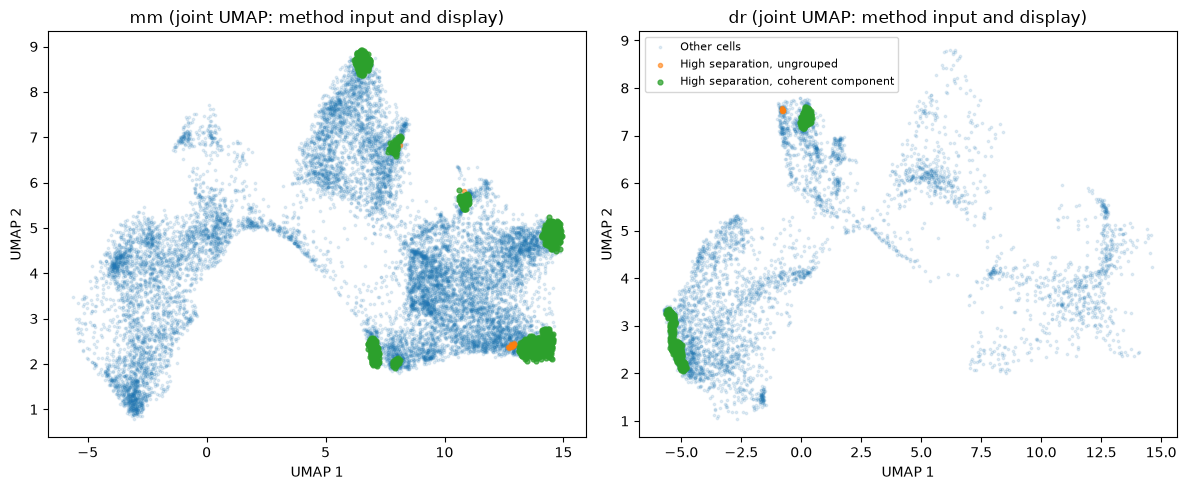

In [14]:
def find_candidate_components(X,info,sep_cells,k=15,min_cells=10):
    if len(info)!=len(X):raise ValueError('Row mismatch for joint coordinates')
    if sep_cells.cell_id.duplicated().any():raise ValueError('Duplicate scored cells')
    indexed=sep_cells.set_index('cell_id')
    if len(indexed)!=len(info) or not pd.Index(info.cell_id).isin(indexed.index).all():
        raise ValueError('H2 saved result does not cover the current H5AD cell IDs')
    score=indexed.loc[info.cell_id].reset_index()
    candidates=(score.above_species_top_quantile.astype(bool).to_numpy() &
                (score.log_other_over_same_kdist.to_numpy(dtype=float)>0))
    output=info[['cell_id','species','label']].copy().reset_index(drop=True)
    output['log_other_over_same_kdist']=score.log_other_over_same_kdist.to_numpy()
    output['candidate_high_separation']=candidates
    output['candidate_component']=''
    counts=[]
    for sid in ['mm','dr']:
        global_idx=np.flatnonzero(info.species.to_numpy()==sid)
        n=len(global_idx)
        if n<k+2:continue
        # StandardScaler fitted jointly; retain shared coordinates for both species.
        kk=min(k+1,n)
        neigh=NearestNeighbors(n_neighbors=kk,n_jobs=-1).fit(X[global_idx])
        dist,ii=neigh.kneighbors(X[global_idx])
        rows=np.repeat(np.arange(n),kk)
        cols=ii.ravel()
        valid=rows!=cols
        directed=sp.csr_matrix((np.ones(valid.sum(),dtype=np.uint8),(rows[valid],cols[valid])),shape=(n,n))
        mutual=directed.minimum(directed.T).tocsr()
        selected=np.flatnonzero(candidates[global_idx])
        if not len(selected):continue
        induced=mutual[selected,:][:,selected]
        from scipy.sparse.csgraph import connected_components
        ncomp,cids=connected_components(induced,directed=False)
        for c in range(ncomp):
            members=global_idx[selected[cids==c]]
            if len(members)<min_cells:continue
            cid=f'{sid}_component_{len(counts)+1:03d}'
            output.loc[members,'candidate_component']=cid
            subset=output.iloc[members]
            composition=subset.label.value_counts().head(5).to_dict()
            counts.append({'component_id':cid,'species':sid,'n_cells':len(members),
                'median_log_separation':float(subset.log_other_over_same_kdist.median()),
                'majority_label':subset.label.mode().iloc[0],
                'majority_fraction':float(subset.label.value_counts(normalize=True).iloc[0]),
                'top_labels_json':json.dumps(composition)})
    return output,pd.DataFrame(counts,columns=[
        'component_id','species','n_cells','median_log_separation',
        'majority_label','majority_fraction','top_labels_json'])


saved=OUTPUT_DIR/'map2_species_separation_cells.csv'
metadata_path=OUTPUT_DIR/'map2_species_separation_metadata.json'
if not saved.exists() or not metadata_path.exists():
    print('H3 skipped: run H2 once to generate its per-cell CSV and metadata.')
else:
    try:
        E,info,provenance=get_joint_context()
    except (FileNotFoundError,ValueError,KeyError) as exc:
        print('H3 not run:',exc)
    else:
        previous=json.loads(metadata_path.read_text())
        if previous['embedding_provenance']!=provenance:
            raise ValueError('Stale H2 CSV: input embedding/H5AD provenance changed; rerun H2.')
        sep=pd.read_csv(saved)
        # Match H2's coordinate scaling and balanced banks exactly; defaults to raw 2D joint UMAP.
        old_params=previous['parameters']
        if previous['seed'] != SEED:
            print('Using saved H2 seed for bank reconstruction:',previous['seed'])
        E_scaled,_,_,_=balanced_joint_coordinates(
            E,info,bank_cap=old_params['bank_max'],seed=previous['seed'],
            scaling=old_params.get('coordinate_scaling','standard'))
        components,component_summary=find_candidate_components(
            E_scaled,info,sep,k=COMPONENT_K,min_cells=COMPONENT_MIN_CELLS)
        components.to_csv(OUTPUT_DIR/'map2_species_separation_components_cells.csv',index=False)
        component_summary.to_csv(OUTPUT_DIR/'map2_species_separation_components_summary.csv',index=False)
        print('Components passing size cutoff:',len(component_summary))
        display(component_summary.sort_values('n_cells',ascending=False).head(30))
        # Visualize on the SAME stored UMAP that is also used as H1/H2/H3 input. No recomputation.
        with open_map2_h5ad() as view:
            if 'X_umap' in view.obsm:
                xy=np.asarray(view.obsm['X_umap'])
                if xy.shape==(len(components),2):
                    fig,axs=plt.subplots(1,2,figsize=(12,5))
                    species=components.species.to_numpy()
                    high=components.candidate_high_separation.to_numpy(dtype=bool)
                    in_component=components.candidate_component.ne('').to_numpy()
                    for ax,sid in zip(axs,['mm','dr']):
                        cur=species==sid
                        ax.scatter(xy[cur & ~high,0],xy[cur & ~high,1],s=3,alpha=.12,label='Other cells')
                        ax.scatter(xy[cur & high & ~in_component,0],xy[cur & high & ~in_component,1],
                                   s=9,alpha=.6,label='High separation, ungrouped')
                        ax.scatter(xy[cur & in_component,0],xy[cur & in_component,1],
                                   s=12,alpha=.75,label='High separation, coherent component')
                        ax.set_title(sid+' (joint UMAP: method input and display)')
                        ax.set(xlabel='UMAP 1',ylabel='UMAP 2')
                    axs[1].legend(loc='best',fontsize=8)
                    fig.tight_layout();plt.show()

## H4. Compare the two species-aware strategies with SAMap — independent (saved files)

Uses **only the saved H1/H2 CSVs**: does not load H5AD, rerun LOF, or recompute the embedding. Comparisons are stratified by species and annotation. H1 percentiles and H2 ranks are **different constructs** and should not be averaged into a single "homology probability." Any apparent inverse relationship to SAMap alignment is a **hypothesis to validate** rather than independent proof.

,species,label,cells,best_alignment,lof_reference_percentile,lof_fraction_above_reference,median_log_species_separation,fraction_positive_species_separation
7,dr,dr_slow muscle cell,912,0.431492,0.5270,0.085526,1.557664,0.975877
5,dr,dr_muscle cell,162,0.180948,0.9525,0.530864,1.471786,0.950617
16,mm,mm_MyoProg_Pax3,1440,0.521722,0.6915,0.081944,1.093214,0.906944
12,mm,mm_MyoB_Mki67,778,0.253402,0.9070,0.170951,1.033009,0.962725
19,mm,mm_MyoProg_Pax7_Mki67,2434,0.535181,0.9330,0.431800,0.993439,0.948644
17,mm,mm_MyoProg_Pax3_Pax7,1251,0.283066,0.7880,0.152678,0.959240,0.988010
9,dr,dr_tendon cell,83,0.384820,0.9710,0.566265,0.934841,0.771084
18,mm,mm_MyoProg_Pax7_Col15,2932,0.438527,0.9010,0.361869,0.754162,0.891542
1,dr,dr_fast muscle cell,2767,0.665090,0.8340,0.263462,0.660906,0.887965
13,mm,mm_MyoC,531,0.281221,0.9900,0.548023,0.598648,0.629002


dr Spearman rank correlation LOF percentile vs species separation: 0.399
mm Spearman rank correlation LOF percentile vs species separation: 0.466


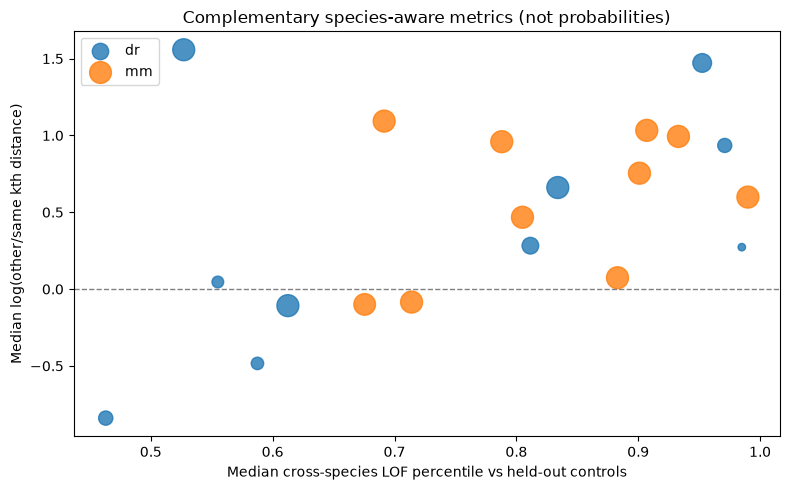

In [15]:
file_a=OUTPUT_DIR/'map2_cross_species_lof_cells.csv'
file_b=OUTPUT_DIR/'map2_species_separation_cells.csv'
if not file_a.exists() or not file_b.exists():
    print('H4 skipped: run H1 and H2 at least once. Existing files:',
          file_a.exists(),file_b.exists())
else:
    metaa=json.loads((OUTPUT_DIR/'map2_cross_species_lof_metadata.json').read_text())
    metab=json.loads((OUTPUT_DIR/'map2_species_separation_metadata.json').read_text())
    if metaa['embedding_provenance']!=metab['embedding_provenance']:
        raise ValueError('H1 and H2 were computed on different embeddings/H5ADs. Rerun one method.')
    a=pd.read_csv(file_a)[['cell_id','species','label','best_score','reference_percentile',
                            'cross_species_lof','above_reference_quantile']]
    b=pd.read_csv(file_b)[['cell_id','species','label','log_other_over_same_kdist',
                            'separation_percentile_within_species','positive_species_separation']]
    joint=a.merge(b,on=['cell_id','species','label'],validate='one_to_one')
    if len(joint)<min(len(a),len(b)):
        warnings.warn('Only overlapping cells compared; check directional sampling limits.')
    type_comparison=joint.groupby(['species','label'],as_index=False).agg(
        cells=('cell_id','size'),best_alignment=('best_score','first'),
        lof_reference_percentile=('reference_percentile','median'),
        lof_fraction_above_reference=('above_reference_quantile','mean'),
        median_log_species_separation=('log_other_over_same_kdist','median'),
        fraction_positive_species_separation=('positive_species_separation','mean'))
    joint.to_csv(OUTPUT_DIR/'map2_species_aware_comparison_cells.csv',index=False)
    type_comparison.to_csv(OUTPUT_DIR/'map2_species_aware_comparison_types.csv',index=False)
    display(type_comparison.sort_values('median_log_species_separation',ascending=False))
    for sid,g in joint.groupby('species'):
        print(sid,'Spearman rank correlation LOF percentile vs species separation:',
              round(g[['reference_percentile','log_other_over_same_kdist']].corr(method='spearman').iloc[0,1],3))
    fig,ax=plt.subplots(figsize=(8,5))
    for sid,g in type_comparison.groupby('species'):
        ax.scatter(g.lof_reference_percentile,g.median_log_species_separation,
                   s=np.minimum(250,20+g.cells),label=sid,alpha=.8)
    ax.axhline(0,color='grey',linestyle='--',linewidth=1)
    ax.set(xlabel='Median cross-species LOF percentile vs held-out controls',
           ylabel='Median log(other/same kth distance)',
           title='Complementary species-aware metrics (not probabilities)')
    ax.legend();fig.tight_layout();plt.show()

## I. Historical within-species baseline comparison — independent (saved CSV)

This section can display the **previous** Isolation Forest / within-species LOF / One-Class SVM results if you ran H0 or still have the earlier saved CSV. It does not rerun the models. Historical scores from a graph-SVD embedding must not be treated as validated homology evidence or directly combined with H1/H2.

,species,label,cells,best_alignment,reciprocal_best,mean_anomaly,median_anomaly,iso,lof,ocsvm
9,dr,dr_tendon cell,83,0.384820,False,0.606322,0.612594,0.731022,0.384337,0.703605
11,mm,mm_MyoB_Jam3,750,0.403372,False,0.578858,0.605583,0.573221,0.474872,0.688480
16,mm,mm_MyoProg_Pax3,750,0.521722,False,0.563217,0.593600,0.592285,0.493077,0.604289
2,dr,dr_fast muscle myoblast,60,0.253402,True,0.559095,0.583584,0.513139,0.651241,0.512904
0,dr,dr_adaxial cell,9,0.287606,False,0.526399,0.561905,0.407790,0.763826,0.407581
18,mm,mm_MyoProg_Pax7_Col15,750,0.438527,False,0.516524,0.554877,0.513561,0.497206,0.538806
12,mm,mm_MyoB_Mki67,750,0.253402,True,0.506385,0.535787,0.489553,0.451377,0.578226
17,mm,mm_MyoProg_Pax3_Pax7,750,0.283066,True,0.509614,0.528148,0.564440,0.449914,0.514488
19,mm,mm_MyoProg_Pax7_Mki67,750,0.535181,True,0.481987,0.520460,0.493301,0.500329,0.452331
15,mm,mm_MyoC_Myh8,750,0.665090,True,0.491575,0.506429,0.518564,0.564560,0.391602


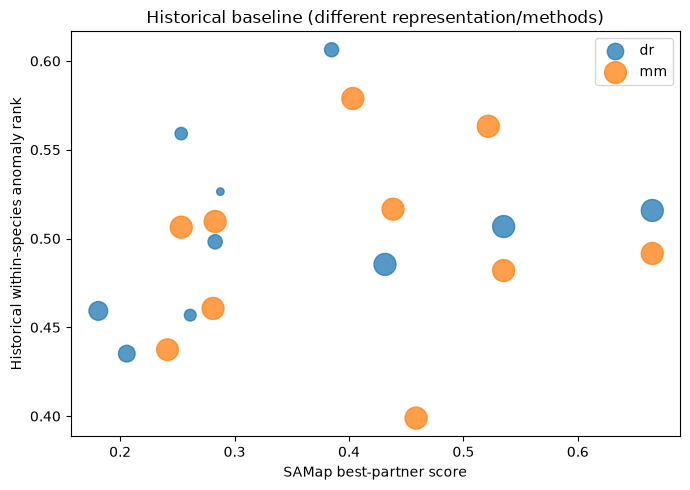

In [16]:
previous=OUTPUT_DIR/'map2_method_comparison_by_cell_type.csv'
if not previous.exists():
    print('No historical baseline CSV; run H0 only if a within-species comparison is needed.')
else:
    old_type=pd.read_csv(previous)
    display(old_type.sort_values('median_anomaly',ascending=False).head(25))
    if 'mean_anomaly' in old_type:
        fig,ax=plt.subplots(figsize=(7,5))
        for sid,g in old_type.groupby('species'):
            ax.scatter(g.best_alignment,g.mean_anomaly,s=np.minimum(250,20+g.cells),label=sid,alpha=.75)
        ax.set(xlabel='SAMap best-partner score',ylabel='Historical within-species anomaly rank',
               title='Historical baseline (different representation/methods)')
        ax.legend();fig.tight_layout();plt.show()

## J. Expression provenance and optional expression-first analyses (each subsection independent)

Scanpy/ElasticNet work on the **expression matrix** rather than the SAMap joint manifold. Both options are off until `.X`/layer preprocessing and gene namespace are verified. These subsections never rerun SAMap and never modify the on-disk H5AD. **Do not interpret species-exclusive prefixed structural zeros as gene regulation.**

In [17]:
# J0 — A small, read-only backed expression sample, no other section prerequisites.
with open_map2_h5ad() as adata:
    print('X shape:',adata.shape,'dtype:',getattr(adata.X,'dtype','unknown'))
    print('layers:',list(adata.layers.keys()),'raw:',adata.raw is not None)
    print('var_names sample:',list(adata.var_names[:15]))
    rng=np.random.default_rng(SEED+300)
    rows=np.sort(rng.choice(adata.n_obs,size=min(15,adata.n_obs),replace=False))
    chunk=adata[rows,:min(250,adata.n_vars)].X
    values=chunk.data if sp.issparse(chunk) else np.asarray(chunk).ravel()
    print('Sample nonzero/sparse-storage values:',pd.Series(values).describe(percentiles=[.5,.9,.99]).to_dict() if len(values) else {})

X shape: (20000, 77556) dtype: float32
layers: ['X_disp'] raw: False
var_names sample: ['mm_4933401J01Rik', 'mm_Gm26206', 'mm_Xkr4', 'mm_Gm18956', 'mm_Gm37180', 'mm_Gm37363', 'mm_Gm37686', 'mm_Gm1992', 'mm_Gm37329', 'mm_Gm7341', 'mm_Gm38148', 'mm_Gm19938', 'mm_Gm10568', 'mm_Gm38385', 'mm_Gm27396']
Sample nonzero/sparse-storage values: {'count': 54.0, 'mean': 1.7351595163345337, 'std': 0.5816291570663452, 'min': 1.0522172451019287, '50%': 1.6269915699958801, '90%': 2.6512075662612915, '99%': 3.091092109680176, 'max': 3.091092109680176}


### J1. Optional within-species Scanpy marker screening — independent

Set `RUN_SCANPY_MARKERS=True` and `EXPRESSION_MATRIX_STATE` in Setup 2 **only after verifying matrix provenance**. Use of the source H5AD is read-only, and only a temporary subset is normalized when the source is counts.

In [18]:
def run_scanpy_marker_section():
    with open_map2_h5ad() as adata:
        cell_info=infer_cell_info(adata)
        rng=np.random.default_rng(SEED+401)
        scanpy_markers=[]
        if adata is None or cell_info is None:
            print('Scanpy marker analysis skipped: H5AD and resolved cell metadata are required.')
        elif EXPRESSION_MATRIX_STATE not in ('counts','log1p_normalized'):
            raise ValueError("Before enabling Scanpy markers, set EXPRESSION_MATRIX_STATE to 'counts' or 'log1p_normalized' based on verified provenance.")
        else:
            targets=['dr_adaxial cell','dr_slow muscle cell','dr_slow muscle myoblast',
                     'dr_fast muscle cell','mm_MyoC_Myh8','mm_MyoProg_Pax3']
            feature_names=np.asarray(adata.var_names.astype(str))
            for sid in ('mm','dr'):
                per_species=np.flatnonzero((cell_info['species']==sid).to_numpy() &
                                           (cell_info['label']!='').to_numpy())
                if len(per_species)<80:
                    print('SKIP',sid,'too few annotated cells'); continue
                gene_idx=np.flatnonzero(np.char.startswith(feature_names.astype(str), sid+'_'))
                if len(gene_idx)<100:
                    if not ALLOW_UNPREFIXED_FEATURES:
                        print('SKIP',sid, 'cannot verify species-specific feature namespace. Inspect .var_names and set ALLOW_UNPREFIXED_FEATURES only if valid.')
                        continue
                    gene_idx=np.arange(adata.n_vars)
                # A capped, seeded subset controls memory. Original AnnData remains read-only.
                if len(per_species)>MAX_CELLS_FOR_SCANPY_MARKERS:
                    per_species=np.sort(rng.choice(per_species, MAX_CELLS_FOR_SCANPY_MARKERS, replace=False))
                tmp=adata[per_species,gene_idx].to_memory()
                if EXPRESSION_LAYER is not None:
                    if EXPRESSION_LAYER not in tmp.layers:
                        raise KeyError(f'Missing expression layer: {EXPRESSION_LAYER}')
                    tmp.X=tmp.layers[EXPRESSION_LAYER].copy()
                tmp.obs['wp3_cell_type']=pd.Categorical(cell_info['label'].iloc[per_species].to_numpy())
                if EXPRESSION_MATRIX_STATE == 'counts':
                    sc.pp.normalize_total(tmp, target_sum=1e4)
                    sc.pp.log1p(tmp)
                else:
                    print('Using verified pre-existing log1p-normalized expression for',sid)
                sc.pp.filter_genes(tmp, min_cells=5)
                if tmp.n_vars<20:
                    print('SKIP',sid,'too few expressed features'); continue
                for target in [t for t in targets if t.startswith(sid+'_')]:
                    npos=int((tmp.obs['wp3_cell_type']==target).sum())
                    if npos<30 or tmp.n_obs-npos<30:
                        print('SKIP',target,'insufficient positive / reference cells'); continue
                    key='wp3_markers_'+sid
                    sc.tl.rank_genes_groups(tmp, groupby='wp3_cell_type', groups=[target],
                                            reference='rest', method='wilcoxon', use_raw=False,
                                            key_added=key)
                    result=sc.get.rank_genes_groups_df(tmp, group=target, key=key)
                    result.insert(0,'cell_type',target)
                    result.insert(1,'species',sid)
                    display(result.head(12))
                    scanpy_markers.append(result)
                del tmp
            if scanpy_markers:
                pd.concat(scanpy_markers,ignore_index=True).to_csv(
                    OUTPUT_DIR/'map2_scanpy_within_species_markers.csv', index=False)

if RUN_SCANPY_MARKERS:
    run_scanpy_marker_section()
else:
    print('J1 disabled. Verify EXPRESSION_MATRIX_STATE and set RUN_SCANPY_MARKERS=True to run.')

J1 disabled. Verify EXPRESSION_MATRIX_STATE and set RUN_SCANPY_MARKERS=True to run.


### J2. Optional one-vs-rest ElasticNet cell-type signatures — independent

The goal is **within-species cell-type classification**, not species classification using non-overlapping gene namespaces. Performance and coefficients describe discriminative patterns, not causality or homology. The source H5AD remains backed/read-only and no previous notebook section is required.

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, balanced_accuracy_score

def run_elasticnet_section():
    with open_map2_h5ad() as adata:
        cell_info=infer_cell_info(adata)
        rng=np.random.default_rng(SEED+402)
        expression_signatures=[]
        if adata is None or cell_info is None:
            raise RuntimeError('Expression models require an available H5AD with matching metadata.')
        if EXPRESSION_MATRIX_STATE not in ('counts', 'log1p_normalized'):
            raise ValueError('Set EXPRESSION_MATRIX_STATE to verified counts or log1p_normalized before enabling expression models.')
        # A within-species one-vs-rest model of cell identity (Brito et al. style),
        # not a species classifier. Never infer counts from the magnitude of .X.
        targets=['dr_adaxial cell','dr_slow muscle cell','dr_fast muscle cell',
                 'mm_MyoC_Myh8','mm_MyoProg_Pax3']
        feature_names=np.asarray(adata.var_names.astype(str))
        for target in targets:
            sid=target.split('_',1)[0]
            pos=np.flatnonzero((cell_info.label==target).to_numpy())
            neg=np.flatnonzero(((cell_info.species==sid)&(cell_info.label!=target)&
                                (cell_info.label!='')).to_numpy())
            if len(pos)<40 or len(neg)<40:
                print('SKIP',target,'insufficient positive or negative cells');continue
            max_each=min(550,len(pos),len(neg))
            rows=np.sort(np.r_[rng.choice(pos,max_each,replace=False),
                               rng.choice(neg,max_each,replace=False)])

            species_gene_mask=np.fromiter((g.startswith(sid+'_') for g in feature_names),
                                          dtype=bool,count=len(feature_names))
            if species_gene_mask.sum() < 100 and not ALLOW_UNPREFIXED_FEATURES:
                print('SKIP',target,'species-specific gene namespace not verified; inspect .var_names')
                continue
            genes=np.flatnonzero(species_gene_mask) if species_gene_mask.sum()>=100 else np.arange(adata.n_vars)
            # Only a small subset is read into memory. The original H5AD remains backed/read-only.
            tmp=adata[rows,genes].to_memory()
            if EXPRESSION_LAYER is not None:
                if EXPRESSION_LAYER not in tmp.layers:
                    raise KeyError(f'Missing expression layer: {EXPRESSION_LAYER}')
                tmp.X=tmp.layers[EXPRESSION_LAYER].copy()
            if EXPRESSION_MATRIX_STATE=='counts':
                # Scanpy handles the normalization of this temporary analysis copy.
                sc.pp.normalize_total(tmp,target_sum=1e4)
                sc.pp.log1p(tmp)
            X=tmp.X
            if sp.issparse(X):
                X=X.tocsr().astype(np.float32)
                present=np.asarray((X>0).sum(axis=0)).ravel()
                minimum=float(min(0, X.data.min())) if X.nnz else 0.0
            else:
                X=np.asarray(X,dtype=np.float32)
                present=(X>0).sum(axis=0)
                minimum=float(X.min()) if X.size else 0.0
            if minimum < -1e-8:
                raise ValueError('Negative expression values detected: verify .X/layer provenance.')
            keep=present>=5
            X=X[:,keep]
            names=np.asarray(tmp.var_names.astype(str))[keep]
            if len(names)<10:
                print('SKIP',target,'too few expressed features');continue
            # Reduce model size using variance estimated on the current (normalized) scale.
            if X.shape[1]>5000:
                mean=np.asarray(X.mean(axis=0)).ravel()
                second=np.asarray(X.power(2).mean(axis=0)).ravel() if sp.issparse(X) else (X**2).mean(axis=0)
                var=np.maximum(0,second-mean**2)
                inds=np.argsort(var)[-5000:]
                X=X[:,inds]; names=names[inds]
            y=(cell_info.label.iloc[rows].to_numpy()==target).astype(int)
            itrain,itest=train_test_split(np.arange(len(y)),test_size=.25,
                                         stratify=y,random_state=SEED)
            scaler=StandardScaler(with_mean=not sp.issparse(X))
            Ztrain=scaler.fit_transform(X[itrain]); Ztest=scaler.transform(X[itest])
            model=LogisticRegression(penalty='elasticnet',solver='saga',l1_ratio=.5,
                                     C=.25,class_weight='balanced',max_iter=2500,
                                     random_state=SEED,n_jobs=1)
            with warnings.catch_warnings(record=True) as captured:
                model.fit(Ztrain,y[itrain])
                if captured:
                    print('Model warnings:',[str(c.message)[:130] for c in captured[:2]])
            prob=model.predict_proba(Ztest)[:,1]
            print('Performance',target,'balanced accuracy',
                  round(balanced_accuracy_score(y[itest],prob>=.5),3),
                  'ROC AUC',round(roc_auc_score(y[itest],prob),3),
                  'average precision',round(average_precision_score(y[itest],prob),3))
            coef=model.coef_.ravel()
            sig=pd.DataFrame({'cell_type':target,'gene':names,'coef':coef,
                              'abs_coef':np.abs(coef),'positive_signature':coef>0})
            sig=sig[sig.coef!=0].sort_values('coef',ascending=False)
            display(sig.head(15))
            expression_signatures.append(sig)
            del tmp
        if expression_signatures:
            pd.concat(expression_signatures,ignore_index=True).to_csv(
                OUTPUT_DIR/'map2_elasticnet_signatures.csv',index=False)

if RUN_EXPRESSION_MODELS:
    run_elasticnet_section()
else:
    print('J2 disabled. Verify EXPRESSION_MATRIX_STATE and set RUN_EXPRESSION_MODELS=True to run.')

J2 disabled. Verify EXPRESSION_MATRIX_STATE and set RUN_EXPRESSION_MODELS=True to run.


## K. Output inventory and interpretation (independent)

This cell **only reads the output directory**. Every method writes its own `.csv` and `.json` metadata so you can rerun H1 without losing H2, rerun H3 without refitting H2, or replot H4 without opening the H5AD.

### Minimum evidence before discussing lineage-specific candidates

1. Verified joint mouse–zebrafish UMAP and cell-row identities. **UMAP is only a 2D projection;** observed distances and densities are exploratory.
2. Stability across neighborhood sizes, balanced-bank replicates, and map1 versus map2 gene maps.
3. Coherent, sufficiently sampled cells; exclude QC, developmental-stage, gene-map and integration confounds.
4. Independent expression signatures, gene-family context, and developmental validation.

**Use language such as:** `locally_species-separated`, `poorly represented by reference atlas`, or `candidate lineage-specific expression state`—not `non-homologous cell type` from an anomaly score alone.
**Current configuration:** H1/H2/H3 all work on `adata.obsm['X_umap']`. This avoids rerunning SAMap, but UMAP can alter distances, densities, cluster sizes, and connectivity; these results cannot on their own establish lineage-specific cell types. If a faithful high-dimensional joint embedding becomes available, rerun H1/H2 with it and compare stability.


In [20]:
print('Output folder:',OUTPUT_DIR.resolve())
if not OUTPUT_DIR.exists():
    print('Output directory does not exist yet.')
else:
    files=sorted(p for p in OUTPUT_DIR.glob('map2_*') if p.is_file())
    display(pd.DataFrame([{'file':p.name,'size_kb':round(p.stat().st_size/1024,1)} for p in files]))
    for name in ('map2_cross_species_lof_metadata.json','map2_species_separation_metadata.json'):
        p=OUTPUT_DIR/name
        if p.exists():
            meta=json.loads(p.read_text())
            print(name,'→',meta['embedding_provenance'])

Output folder: /home/giatraskon/Desktop/Repositories & Projects/BioHackEU2026/wp3_results


,file,size_kb
0,map2_cell_novelty_scores.csv,2393.8
1,map2_cross_species_lof_cells.csv,3440.6
2,map2_cross_species_lof_controls.csv,203.2
3,map2_cross_species_lof_metadata.json,1.6
4,map2_cross_species_lof_types.csv,2.7
5,map2_gene_pairs_long.csv,3067.0
6,map2_method_comparison_by_cell_type.csv,2.9
7,map2_species_aware_comparison_cells.csv,2789.9
8,map2_species_aware_comparison_types.csv,2.3
9,map2_species_separation_cells.csv,4379.3


map2_cross_species_lof_metadata.json → {'source': 'obsm', 'key': 'X_umap', 'exploratory_only': True, 'coordinates': 'stored joint 2D UMAP', 'dimensions': [20000, 2], 'h5ad': {'path': '/home/giatraskon/Desktop/Repositories & Projects/BioHackEU2026/samap_mm_dr_map2_20K.h5ad', 'size': 109204821, 'mtime_ns': 1794241394000000000}, 'coordinate_scaling': 'none'}
map2_species_separation_metadata.json → {'source': 'obsm', 'key': 'X_umap', 'exploratory_only': True, 'coordinates': 'stored joint 2D UMAP', 'dimensions': [20000, 2], 'h5ad': {'path': '/home/giatraskon/Desktop/Repositories & Projects/BioHackEU2026/samap_mm_dr_map2_20K.h5ad', 'size': 109204821, 'mtime_ns': 1794241394000000000}, 'coordinate_scaling': 'none'}
